<div style="text-align:center; line-height:1.6">

МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ<br>
Новосибирский государственный технический университет<br>
Факультет автоматики и вычислительной техники

<br>

# ОТЧЁТ
## по лабораторной работе № 2
### «Классификация. Нейронные сети»

Дисциплина «Методы анализа данных» · Датасет: **Titanic Survival** (Kaggle)

</div>

<div style="text-align:right">
Выполнил: студент гр. АВТ-313 Савченко В.Э.<br>
Проверил: Антонянц Е.Н.
</div>

<div style="text-align:center">Новосибирск, 2026</div>

---

## Содержание

1. Введение
2. Выбор и подготовка датасета
3. Разбиение выборки
4. Методы классификации
5. Настройка гиперпараметров (5.1 Наивный Байес · 5.2 Дерево решений · 5.3 LDA · 5.4 SVM · 5.5 kNN · 5.6 Итог настройки)
6. Нейронная сеть на TensorFlow (6.1 Архитектура · 6.2–6.6 Эксперименты · 6.7 Итоговая сеть · 6.8 TensorBoard)
7. Сравнительный анализ
8. Заключение
9. Список источников

# 1. Введение

**Цель работы** — изучение методов классификации данных, реализованных в библиотеке Scikit-Learn,
и знакомство с нейронными сетями на TensorFlow с визуализацией обучения в TensorBoard.

**Задачи:**

1. Выбрать и подготовить датасет для бинарной классификации: очистка, заполнение пропусков,
   кодирование и масштабирование признаков.
2. Построить классификаторы пятью методами: наивный Байес (GaussianNB, MultinomialNB, ComplementNB,
   BernoulliNB), дерево решений, линейный дискриминантный анализ, метод опорных векторов,
   метод k ближайших соседей.
3. Настроить гиперпараметры каждого метода и исследовать их влияние на качество.
4. Построить нейронную сеть на TensorFlow/Keras, провести эксперименты с числом эпох, размером
   батча, числом слоёв и нейронов, функциями активации; визуализировать обучение в TensorBoard.
5. Сравнить все модели по метрикам Accuracy, Precision, Recall, F1-score, ROC-AUC и выбрать лучший
   подход для данного датасета.

**Метрики.** Положительный класс — «выжил» (1). TP — выживший, предсказанный как выживший;
FP — погибший, предсказанный как выживший; FN — выживший, предсказанный как погибший; TN — погибший,
предсказанный как погибший.

| Метрика | Формула | Смысл для задачи |
|---|---|---|
| Accuracy | (TP + TN) / N | доля верных ответов среди всех пассажиров |
| Precision | TP / (TP + FP) | из тех, кого модель назвала выжившими, — доля действительно выживших |
| Recall | TP / (TP + FN) | из всех выживших — доля, которую модель нашла |
| F1-score | 2·P·R / (P + R) | среднее гармоническое precision и recall; низкое, если хотя бы одна из них низкая |
| ROC-AUC | площадь под ROC-кривой | вероятность того, что случайный выживший получит от модели более высокую оценку, чем случайный погибший; не зависит от порога |

Ориентир: модель, всегда отвечающая «погиб», даёт accuracy 0,615 (доля погибших), но recall,
precision и F1 у неё равны нулю, а ROC-AUC — 0,5. Любой полезный классификатор должен быть
заметно лучше.

In [1]:
# Импорт библиотек
import os, re, glob, time, warnings
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"           # тише логи TensorFlow
import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)               # фиксирует seed Python, NumPy и TF
tf.config.experimental.enable_op_determinism()     # детерминированные операции TF

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
pd.set_option("display.width", 140)
os.makedirs("figs", exist_ok=True)

def show(fig, name):
    """Сохраняет рисунок в figs/ и выводит его в ноутбуке."""
    fig.tight_layout()
    fig.savefig(f"figs/{name}.png", bbox_inches="tight")
    plt.show()

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


# 2. Выбор и подготовка датасета

**Датасет:** Titanic — Machine Learning from Disaster (Kaggle), файл `train.csv`: 891 пассажир
«Титаника» с известным исходом. **Задача:** по данным пассажира предсказать, выжил ли он
(`Survived`: 1 — выжил, 0 — погиб). Это бинарная классификация.

Выбор обоснован тем, что датасет требует полноценной подготовки (пропуски, категориальные
и текстовые признаки, асимметричные числовые) и при этом хорошо интерпретируется: на нём легко
проверить, совпадает ли поведение модели со здравым смыслом («женщины и дети — первыми»).

| Признак | Тип | Описание |
|---|---|---|
| `PassengerId` | id | номер пассажира — не несёт информации, удаляется |
| `Survived` | **целевой**, бинарный | 1 — выжил, 0 — погиб |
| `Pclass` | порядковый | класс билета: 1, 2, 3 (социально-экономический статус) |
| `Name` | текст | имя с обращением (Mr, Mrs, Miss, Master…) |
| `Sex` | категориальный | пол |
| `Age` | числовой | возраст, лет |
| `SibSp` | числовой | число братьев/сестёр и супругов на борту |
| `Parch` | числовой | число родителей и детей на борту |
| `Ticket` | текст | номер билета — почти уникален, удаляется |
| `Fare` | числовой | стоимость билета |
| `Cabin` | текст | номер каюты |
| `Embarked` | категориальный | порт посадки: C — Шербур, Q — Квинстаун, S — Саутгемптон |

In [2]:
# Titanic (Kaggle: "Titanic — Machine Learning from Disaster", файл train.csv)
CSV = "titanic.csv"
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
if not os.path.exists(CSV):
    urllib.request.urlretrieve(URL, CSV)

df = pd.read_csv(CSV)
print("Размер:", df.shape)
df.head()

Размер: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()
print("\nПропуски:")
na = df.isna().sum()
print(pd.DataFrame({"пропусков": na, "%": (na / len(df) * 100).round(1)})[na > 0])
print("\nДубликатов строк:", df.duplicated().sum())
print("\nБаланс классов (Survived):")
print(pd.DataFrame({"n": df.Survived.value_counts(), "%": (df.Survived.value_counts(normalize=True) * 100).round(1)}))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Пропуски:
          пропусков     %
Age             177  19.9
Cabin           687  77.1
Embarked          2   0.2

Дубликатов строк: 0

Баланс классов (Survived):
            n     %
Survived           
0         549  61.6
1         342  38.4


**Что видно.**

- **Пропуски:** `Age` — 177 (19,9 %), `Cabin` — 687 (77,1 %), `Embarked` — 2 (0,2 %). Дубликатов нет.
- **Классы несбалансированы умеренно:** погибли 549 (61,6 %), выжили 342 (38,4 %). Это не критично
  для обучения, но означает, что accuracy нужно сравнивать с базой 0,616, а при разбиении выборки
  сохранять пропорцию классов (стратификация).

In [4]:
num = ["Age", "SibSp", "Parch", "Fare"]
d = df[num].describe().T
d["skew"] = df[num].skew()          # асимметрия
d["kurtosis"] = df[num].kurtosis()  # избыточный эксцесс
d.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00,0.39,0.18
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00,3.70,17.88
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00,2.75,9.78
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33,4.79,33.40


**Описательные статистики.** `Age` распределён почти симметрично (skew 0,39), средний возраст 29,7 лет.
`Fare` — сильнейшая правосторонняя асимметрия (skew 4,79, эксцесс 33,4): медиана 14,45, максимум 512 —
несколько очень дорогих билетов первого класса. `SibSp` и `Parch` тоже скошены: у большинства
родственников на борту нет. Для `Fare` выполняется логарифмирование `log(1 + Fare)`, чтобы выбросы
не доминировали в методах, основанных на расстояниях (kNN, SVM).

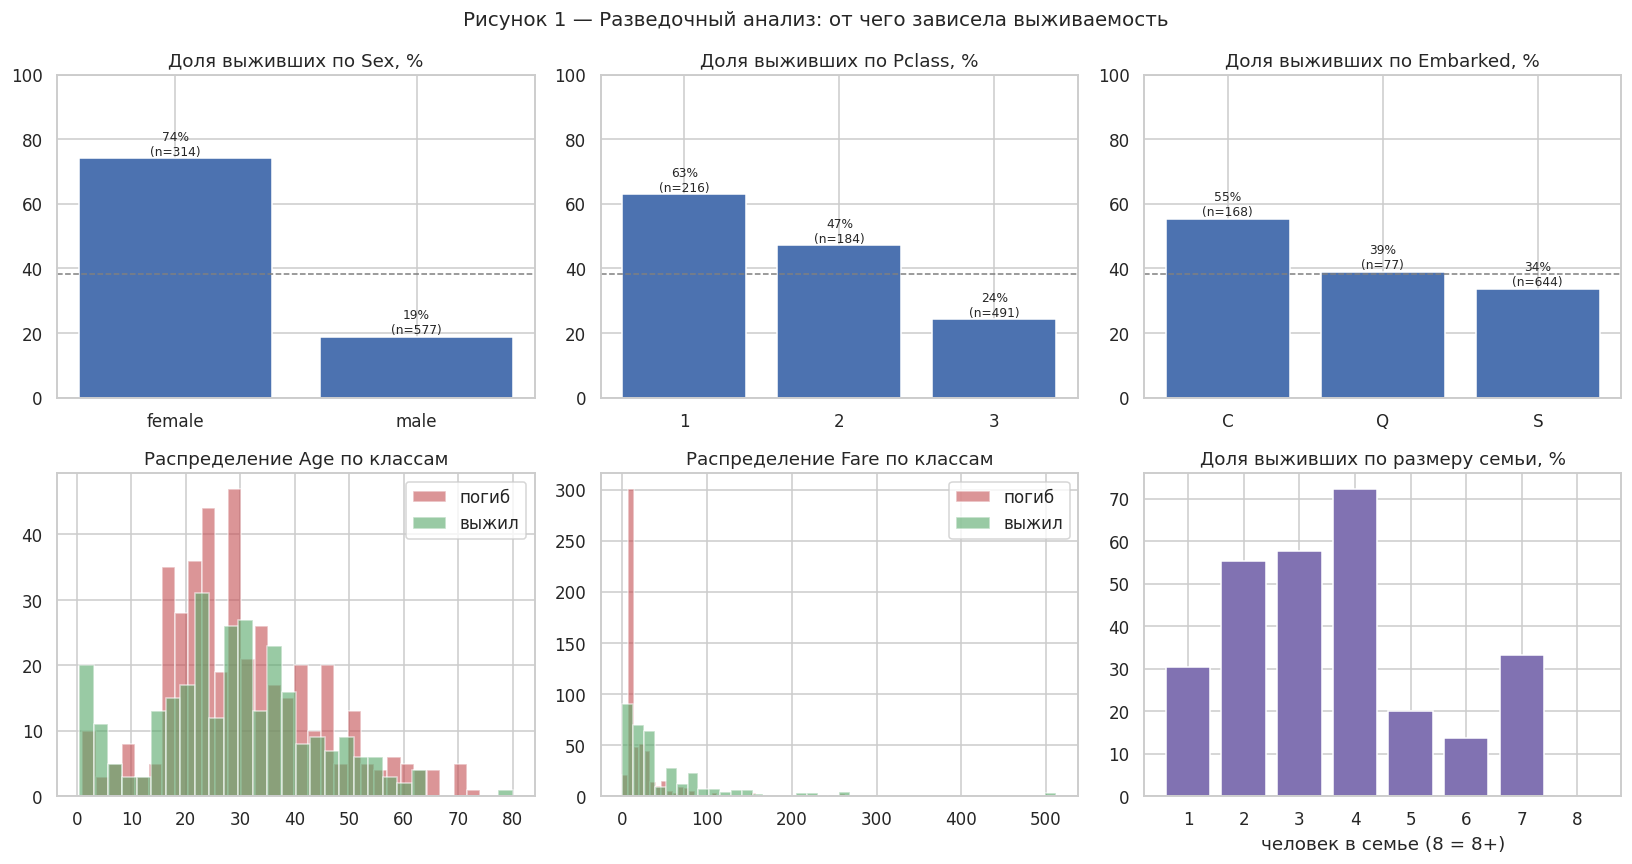

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
# доля выживших по категориальным признакам
for ax, col in zip(axes[0], ["Sex", "Pclass", "Embarked"]):
    r = df.groupby(col)["Survived"].agg(["mean", "size"])
    bars = ax.bar(r.index.astype(str), r["mean"] * 100, color="#4C72B0")
    ax.bar_label(bars, labels=[f"{m*100:.0f}%\n(n={n})" for m, n in zip(r["mean"], r["size"])], fontsize=8)
    ax.axhline(df.Survived.mean() * 100, ls="--", color="gray", lw=1)
    ax.set_title(f"Доля выживших по {col}, %"); ax.set_ylim(0, 100)
# распределения числовых признаков по классам
for ax, col, bins in [(axes[1][0], "Age", 30), (axes[1][1], "Fare", 40)]:
    for v, c, lab in [(0, "#C44E52", "погиб"), (1, "#55A868", "выжил")]:
        ax.hist(df.loc[df.Survived == v, col].dropna(), bins=bins, alpha=0.6, color=c, label=lab)
    ax.set_title(f"Распределение {col} по классам"); ax.legend()
fam = (df.SibSp + df.Parch + 1)
r = df.groupby(fam.clip(upper=8))["Survived"].mean() * 100
axes[1][2].bar(r.index.astype(str), r.values, color="#8172B2")
axes[1][2].set_title("Доля выживших по размеру семьи, %"); axes[1][2].set_xlabel("человек в семье (8 = 8+)")
fig.suptitle("Рисунок 1 — Разведочный анализ: от чего зависела выживаемость", fontsize=13)
show(fig, "01_eda")

**Комментарий к рисунку 1.** Выживаемость определялась несколькими факторами, и все они видны сразу:

- **Пол** — главный фактор: выжили 74 % женщин и только 19 % мужчин (правило «женщины и дети первыми»).
- **Класс билета:** 63 % в первом классе, 47 % во втором, 24 % в третьем — каюты третьего класса
  находились ниже и дальше от шлюпок.
- **Порт посадки:** в Шербуре (C) выжили 55 %, в Саутгемптоне (S) — 34 %. Это не прямой эффект,
  а следствие состава: в Шербуре садилось больше пассажиров первого класса.
- **Возраст:** у выживших заметен пик у детей до 10 лет (выжили 61 %), у погибших — пик в 20–30 лет
  (молодые мужчины).
- **Стоимость билета:** у погибших распределение сосредоточено у дешёвых билетов (медиана 10,5),
  у выживших сдвинуто вправо (медиана 26).
- **Размер семьи** — зависимость нелинейная: одиночки выживали в 30 % случаев, семьи из 2–4 человек —
  в 55–72 %, большие семьи (5+) — в 0–33 %. Поэтому полезен признак `FamilySize`, а не только
  `SibSp`/`Parch` по отдельности.

### Предобработка

**Шаг 1. Построчные преобразования** (функция `engineer`): используют только значения своей строки,
поэтому их можно применять до разбиения — утечки нет.

| Новый признак | Как получен | Зачем |
|---|---|---|
| `Title` | обращение из `Name` (Mr, Mrs, Miss, Master; редкие → Rare; Mlle/Ms → Miss, Mme → Mrs) | несёт пол, возраст и статус одновременно: Master — мальчик, Miss — незамужняя девушка |
| `FamilySize` | SibSp + Parch + 1 | размер семьи — нелинейный фактор (рисунок 1) |
| `IsAlone` | FamilySize = 1 | одиночки выживали реже |
| `HasCabin` | Cabin не пуст | 77 % пропусков — восстановить номер каюты нельзя, но сам факт наличия каюты связан с классом (выжили 67 % против 30 %) |
| `Sex_male` | 1 — мужчина | бинарное кодирование пола |
| `Fare_log` | log(1 + Fare) | снятие асимметрии |

Удаляются `PassengerId`, `Name`, `Ticket`, `Cabin` (после извлечения информации), `Sex` и `Fare`
(заменены новыми признаками).

**Шаг 2. Преобразования со статистиками** (функция `make_prep`) выполняются **внутри Pipeline**:
медиана, мода, среднее и стандартное отклонение вычисляются только на тех данных, на которых
вызывается `fit` (обучающая выборка, а при кросс-валидации — обучающая часть каждого фолда).

| Тип признаков | Обработка |
|---|---|
| Числовые: `Pclass`, `Age`, `SibSp`, `Parch`, `FamilySize`, `Fare_log` | пропуски `Age` → медиана + **флаг пропуска** `missingindicator_Age`; затем стандартизация (StandardScaler); для MultinomialNB, ComplementNB и BernoulliNB — нормализация в [0, 1] (MinMaxScaler), так как им нужны неотрицательные признаки |
| Бинарные: `Sex_male`, `IsAlone`, `HasCabin` | без изменений (уже 0/1) |
| Категориальные: `Embarked`, `Title` | пропуски → мода; one-hot кодирование |

Флаг пропуска возраста добавлен потому, что сам факт отсутствия возраста информативен: среди
пассажиров без указанного возраста выжили 29 %, среди остальных — 41 %.

In [6]:
def engineer(d):
    """Построчные преобразования (не используют статистики выборки -> утечки нет)."""
    d = d.copy()
    title = d["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    d["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1          # сам пассажир + родственники
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["HasCabin"] = d["Cabin"].notna().astype(int)          # 77 % пропусков -> только флаг наличия
    d["Sex_male"] = (d["Sex"] == "male").astype(int)
    d["Fare_log"] = np.log1p(d["Fare"])                     # снимаем сильную асимметрию Fare
    return d.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "Sex", "Fare"])

data = engineer(df)
y = data.pop("Survived")
X = data

NUM = ["Pclass", "Age", "SibSp", "Parch", "FamilySize", "Fare_log"]
BIN = ["Sex_male", "IsAlone", "HasCabin"]
CAT = ["Embarked", "Title"]
print("Признаки:", NUM + BIN + CAT)
print("\nTitle:", X.Title.value_counts().to_dict())
print("\nДоля выживших по Title, %:", (y.groupby(X.Title).mean() * 100).round(0).to_dict())
X.head()

Признаки: ['Pclass', 'Age', 'SibSp', 'Parch', 'FamilySize', 'Fare_log', 'Sex_male', 'IsAlone', 'HasCabin', 'Embarked', 'Title']

Title: {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}

Доля выживших по Title, %: {'Master': 57.0, 'Miss': 70.0, 'Mr': 16.0, 'Mrs': 79.0, 'Rare': 35.0}


,Pclass,Age,SibSp,Parch,Embarked,Title,FamilySize,IsAlone,HasCabin,Sex_male,Fare_log
0,3,22.0,1,0,S,Mr,2,0,0,1,2.110213
1,1,38.0,1,0,C,Mrs,2,0,1,0,4.280593
2,3,26.0,0,0,S,Miss,1,1,0,0,2.188856
3,1,35.0,1,0,S,Mrs,2,0,1,0,3.990834
4,3,35.0,0,0,S,Mr,1,1,0,1,2.202765


In [7]:
def make_prep(scaler="standard"):
    """Предобработка внутри Pipeline: все статистики (медианы, моды, mean/std, min/max)
       вычисляются только на тех данных, на которых вызывается fit -> без утечки."""
    sc = StandardScaler() if scaler == "standard" else MinMaxScaler()
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),  # Age -> медиана + флаг пропуска
                    ("sc", sc)])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),               # Embarked -> мода
                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM), ("bin", "passthrough", BIN), ("cat", cat, CAT)])

def feature_names(prep):
    return [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

# 3. Разбиение выборки

Данные разбиваются функцией `train_test_split` в соотношении **80/20** с параметром
`stratify=y` — доля выживших в обеих частях одинакова. Seed фиксирован (`random_state=42`).

- **Обучающая выборка (712)** — используется для обучения и подбора гиперпараметров
  через **5-блочную стратифицированную кросс-валидацию** (`StratifiedKFold`).
- **Тестовая выборка (179)** — используется один раз, для итоговой оценки в разделе 7.
- Для нейросети из обучающей выборки дополнительно выделяется **валидационная** (20 %, 143 чел.) —
  по ней строятся кривые validation loss/accuracy и работает ранняя остановка.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)       # stratify сохраняет долю классов
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"train: {X_train.shape}, доля выживших {y_train.mean()*100:.1f} %")
print(f"test:  {X_test.shape}, доля выживших {y_test.mean()*100:.1f} %")

P = make_prep().fit(X_train)
print(f"\nПосле предобработки признаков: {len(feature_names(P))}")
print(feature_names(P))

train: (712, 11), доля выживших 38.3 %
test:  (179, 11), доля выживших 38.5 %

После предобработки признаков: 18
['Pclass', 'Age', 'SibSp', 'Parch', 'FamilySize', 'Fare_log', 'missingindicator_Age', 'Sex_male', 'IsAlone', 'HasCabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


Пропорция классов сохранена: 38,3 % и 38,5 %. После предобработки получается 18 признаков:
6 числовых, флаг пропуска возраста, 3 бинарных, 3 столбца порта посадки и 5 столбцов обращения.

In [9]:
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
MAIN = "accuracy"        # метрика для подбора гиперпараметров

def scores_of(model, Xt):
    """Непрерывная оценка «уверенности» для ROC: вероятность или значение решающей функции."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(Xt)[:, 1]
    return model.decision_function(Xt)

def test_metrics(model, Xt=None, yt=None):
    Xt = X_test if Xt is None else Xt
    yt = y_test if yt is None else yt
    p = model.predict(Xt)
    return {"accuracy": accuracy_score(yt, p), "precision": precision_score(yt, p),
            "recall": recall_score(yt, p), "f1": f1_score(yt, p),
            "roc_auc": roc_auc_score(yt, scores_of(model, Xt))}

def cv_metrics(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING)
    return {k: r[f"test_{k}"].mean() for k in SCORING} | {"roc_auc_std": r["test_roc_auc"].std()}

def tune(pipe, grid):
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit=MAIN, n_jobs=-1)
    gs.fit(X_train, y_train)
    return gs

def results_table(gs, params, top=8):
    r = pd.DataFrame(gs.cv_results_)
    cols = [f"param_{p}" for p in params] + [f"mean_test_{k}" for k in SCORING] + ["std_test_roc_auc"]
    t = r.sort_values(f"rank_test_{MAIN}")[cols].head(top)
    t.columns = [c.replace("param_clf__", "").replace("mean_test_", "CV ") for c in t.columns]
    return t.round(4).reset_index(drop=True)

RESULTS = {}      # лучшая настроенная модель каждого метода
DEFAULT = {}      # та же модель с параметрами по умолчанию

baseline = Pipeline([("prep", make_prep()), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
print("Базовая модель (всегда «погиб»): accuracy на тесте =",
      round(accuracy_score(y_test, baseline.predict(X_test)), 4))

Базовая модель (всегда «погиб»): accuracy на тесте = 0.6145


Гиперпараметры подбираются `GridSearchCV` по сетке значений; для каждой комбинации считаются все
пять метрик на 5-блочной CV, а лучшая комбинация выбирается **по accuracy** (`refit="accuracy"`).

Почему accuracy: в задаче нет асимметрии стоимости ошибок (ошибиться в выжившем и в погибшем
одинаково плохо), а дисбаланс классов умеренный (62/38). Подбор по ROC-AUC был опробован, но для SVM
он выбрал сильно регуляризованную модель с хорошим ранжированием и плохим порогом
(accuracy 0,795 против 0,829 у модели по умолчанию) — для итогового «да/нет» это хуже.

# 4. Методы классификации

**4.1. Наивный байесовский классификатор.** Использует теорему Байеса:
P(класс | x) ∝ P(класс)·∏ P(xⱼ | класс). «Наивность» — предположение, что признаки **условно
независимы** при известном классе; благодаря ему правдоподобие распадается на произведение
одномерных распределений и оценивается по очень малому числу данных. Варианты различаются моделью
P(xⱼ | класс):

- **GaussianNB** — нормальное распределение (для непрерывных признаков); параметр `var_smoothing`
  добавляет долю наибольшей дисперсии ко всем дисперсиям для численной устойчивости;
- **MultinomialNB** — мультиномиальное распределение (для счётчиков, частот слов); `alpha` —
  сглаживание Лапласа, защита от нулевых вероятностей;
- **ComplementNB** — модификация MultinomialNB, оценивающая параметры по **дополнению** класса;
  устойчивее при дисбалансе классов;
- **BernoulliNB** — распределение Бернулли (для бинарных признаков); `binarize` — порог
  превращения признака в 0/1.

**4.2. Дерево решений.** Рекурсивно делит выборку на части по условиям вида «признак ≤ порог»,
на каждом шаге выбирая разбиение с максимальным снижением неоднородности — **индекса Джини**
G = 1 − Σpₖ² или **энтропии** H = −Σpₖ·log₂pₖ. Прогноз — мажоритарный класс листа. Плюсы:
интерпретируемость, не нужна стандартизация, ловит нелинейности и взаимодействия. Минус — склонно
к переобучению; ограничивается параметрами `max_depth` (глубина), `min_samples_leaf` (минимум
объектов в листе), `criterion`.

**4.3. Линейный дискриминантный анализ (LDA).** Генеративная модель: каждый класс описывается
многомерным нормальным распределением с **общей ковариационной матрицей** Σ. Отсюда граница между
классами линейна: δ(x) = wᵀx + b, w = Σ⁻¹(μ₁ − μ₀). Геометрически LDA ищет направление, на котором
отношение межклассового разброса к внутриклассовому максимально (критерий Фишера). Параметры:
`solver` (svd, lsqr, eigen) и `shrinkage` — сжатие оценки Σ к диагональной матрице, полезное при
малых выборках и коррелированных признаках.

**4.4. Метод опорных векторов (SVM).** Ищет разделяющую гиперплоскость с **максимальным зазором**
(margin) между классами; решение определяется только ближайшими к границе объектами — опорными
векторами. Параметр `C` — штраф за нарушение зазора: малое C — широкий зазор и сильная
регуляризация, большое C — модель стремится классифицировать всё обучение без ошибок. **Ядра**
(`kernel`) позволяют строить нелинейную границу без явного перехода в новое пространство:
linear, poly (полиномиальное, параметр `degree`), rbf (радиальное, exp(−γ‖x − x′‖²); `gamma`
задаёт радиус влияния одного объекта).

**4.5. Метод k ближайших соседей (kNN).** Ленивый метод: обучение — это просто запоминание выборки;
для нового объекта находятся k ближайших по расстоянию и выбирается преобладающий среди них класс.
Параметры: `n_neighbors` (k: малое — переобучение, большое — недообучение), `weights` (uniform —
голоса равны; distance — ближние соседи важнее), `p` — метрика Минковского (1 — манхэттенская,
2 — евклидова). Требует обязательной стандартизации — иначе признак с большим масштабом
определяет расстояние в одиночку.

# 5. Настройка гиперпараметров

Для каждого метода: сравнение с параметрами по умолчанию, поиск по сетке с 5-блочной CV, графики
влияния отдельных параметров. Все цифры в этом разделе — **кросс-валидация на обучающей выборке**;
тестовая выборка не используется.

## 5.1. Наивный Байес

In [10]:
nb_variants = {
    "GaussianNB":    (make_prep("standard"), GaussianNB()),
    "MultinomialNB": (make_prep("minmax"),   MultinomialNB()),      # нужны неотрицательные признаки
    "ComplementNB":  (make_prep("minmax"),   ComplementNB()),
    "BernoulliNB":   (make_prep("minmax"),   BernoulliNB(binarize=0.5)),  # признаки -> 0/1 по порогу
}
rows = []
for name, (prep, clf) in nb_variants.items():
    rows.append({"вариант": name, **cv_metrics(Pipeline([("prep", prep), ("clf", clf)]))})
nb_cmp = pd.DataFrame(rows).set_index("вариант")
print("Таблица 3 — Четыре варианта наивного Байеса (параметры по умолчанию, 5-fold CV)")
nb_cmp.round(4)

Таблица 3 — Четыре варианта наивного Байеса (параметры по умолчанию, 5-fold CV)


,accuracy,precision,recall,f1,roc_auc,roc_auc_std
вариант,,,,,,
GaussianNB,0.8020,0.7162,0.8095,0.7587,0.8630,0.0296
MultinomialNB,0.7992,0.7327,0.7585,0.7430,0.8524,0.0219
ComplementNB,0.7866,0.7035,0.7767,0.7364,0.8524,0.0219
BernoulliNB,0.7978,0.7233,0.7730,0.7457,0.8609,0.0221


**Таблица 3.** С параметрами по умолчанию все четыре варианта близки (accuracy 0,787–0,802), лучший —
**GaussianNB** (0,802 / ROC-AUC 0,863). Он единственный моделирует непрерывные признаки (возраст,
стоимость билета) «естественным» образом. MultinomialNB и ComplementNB рассчитаны на счётчики
(частоты слов) — для них признаки пришлось искусственно перевести в [0, 1], и их ROC-AUC ниже (0,852).
ComplementNB совпадает с MultinomialNB по ROC-AUC (в бинарной задаче их оценки ранжируют объекты
одинаково), но хуже по accuracy. GaussianNB даёт самый высокий recall (0,81) — он «щедро» относит
пассажиров к выжившим.

GaussianNB     лучшие параметры: {'clf__var_smoothing': np.float64(0.03162277660168379)}  CV accuracy = 0.8132


MultinomialNB  лучшие параметры: {'clf__alpha': np.float64(17.78279410038923)}  CV accuracy = 0.8048


ComplementNB   лучшие параметры: {'clf__alpha': np.float64(100.0)}  CV accuracy = 0.8034


BernoulliNB    лучшие параметры: {'clf__alpha': np.float64(100.0), 'clf__binarize': 0.7}  CV accuracy = 0.8104


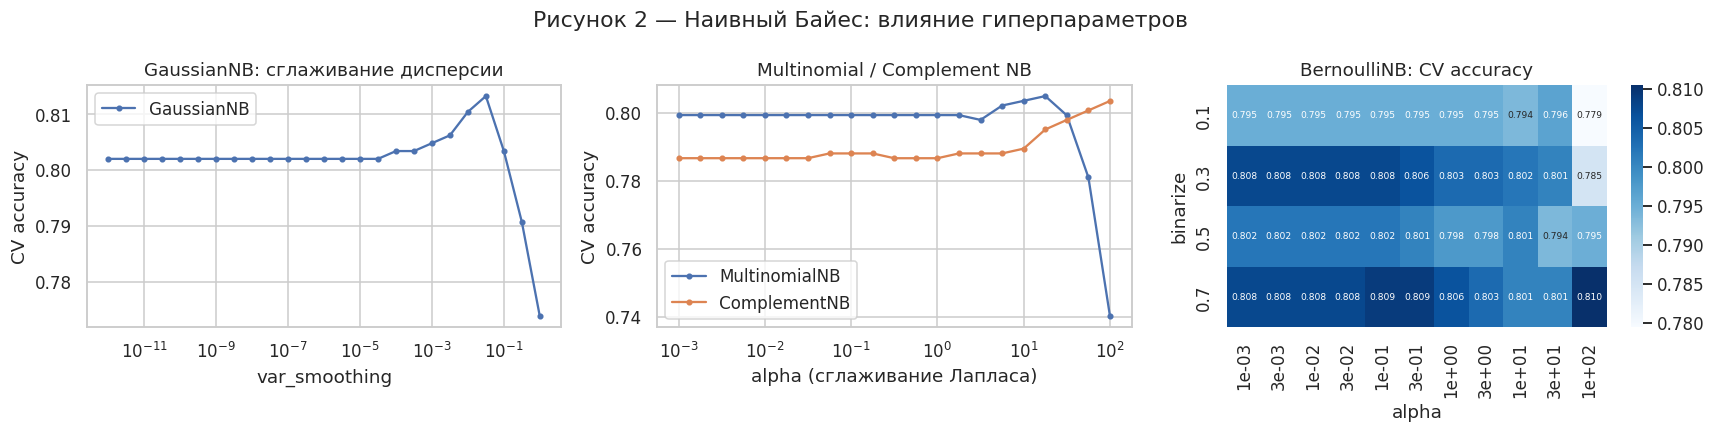


Лучший вариант: GaussianNB


In [11]:
nb_grids = {
    "GaussianNB":    {"clf__var_smoothing": np.logspace(-12, 0, 25)},
    "MultinomialNB": {"clf__alpha": np.logspace(-3, 2, 21)},
    "ComplementNB":  {"clf__alpha": np.logspace(-3, 2, 21)},
    "BernoulliNB":   {"clf__alpha": np.logspace(-3, 2, 11), "clf__binarize": [0.1, 0.3, 0.5, 0.7]},
}
nb_gs = {}
for name, (prep, clf) in nb_variants.items():
    nb_gs[name] = tune(Pipeline([("prep", prep), ("clf", clf)]), nb_grids[name])
    print(f"{name:14s} лучшие параметры: {nb_gs[name].best_params_}  CV accuracy = {nb_gs[name].best_score_:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, ax_i, p in [("GaussianNB", 0, "var_smoothing"), ("MultinomialNB", 1, "alpha"), ("ComplementNB", 1, "alpha")]:
    r = pd.DataFrame(nb_gs[name].cv_results_)
    axes[ax_i].semilogx(r[f"param_clf__{p}"].astype(float), r["mean_test_accuracy"], "o-", ms=3, label=name)
axes[0].set_xlabel("var_smoothing"); axes[0].set_title("GaussianNB: сглаживание дисперсии")
axes[1].set_xlabel("alpha (сглаживание Лапласа)"); axes[1].set_title("Multinomial / Complement NB")
r = pd.DataFrame(nb_gs["BernoulliNB"].cv_results_)
piv = r.pivot_table(index="param_clf__binarize", columns="param_clf__alpha", values="mean_test_accuracy")
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", ax=axes[2], annot_kws={"size": 6},
            xticklabels=[f"{a:.0e}" for a in piv.columns])
axes[2].set_title("BernoulliNB: CV accuracy"); axes[2].set_xlabel("alpha"); axes[2].set_ylabel("binarize")
for a in axes[:2]:
    a.set_ylabel("CV accuracy"); a.legend()
fig.suptitle("Рисунок 2 — Наивный Байес: влияние гиперпараметров")
show(fig, "02_nb")

best_nb = max(nb_gs, key=lambda n: nb_gs[n].best_score_)
print("\nЛучший вариант:", best_nb)
RESULTS["Наивный Байес"] = nb_gs[best_nb].best_estimator_
DEFAULT["Наивный Байес"] = Pipeline([("prep", nb_variants[best_nb][0]), ("clf", nb_variants[best_nb][1])]).fit(X_train, y_train)

**Комментарий к рисунку 2.**

- **GaussianNB:** при `var_smoothing` от 10⁻¹² до ≈ 10⁻⁴ качество не меняется — добавка к дисперсиям
  ничтожна. Оптимум при ≈ 0,03 (accuracy 0,813 против 0,802): сглаживание «расширяет» гауссианы
  и делает оценки вероятностей менее категоричными, что слегка компенсирует нарушенное
  предположение о независимости признаков. При var_smoothing → 1 качество падает: распределения
  становятся настолько широкими, что классы перестают различаться.
- **MultinomialNB / ComplementNB:** при `alpha` до 1 качество постоянно (0,80 и 0,787), затем растёт:
  лучшее `alpha` — 17,8 и 100 соответственно. Сильное сглаживание работает как регуляризация —
  уменьшает влияние «искусственных» частот, полученных из масштабированных непрерывных признаков.
  Но у MultinomialNB при `alpha` = 100 качество обваливается до 0,74: сглаживание становится
  настолько сильным, что распределения признаков в обоих классах почти выравниваются.
- **BernoulliNB:** порог бинаризации влияет сильнее, чем `alpha`: при `binarize` = 0,1 accuracy
  0,795, при 0,3 и 0,7 — 0,808–0,810. Порог определяет, какое значение возраста или цены считать
  «единицей»; `alpha` почти не влияет, кроме крайнего значения 100.

**Итог:** лучший вариант — **GaussianNB с var_smoothing ≈ 0,03**; настройка дала +1,1 п. п. accuracy.
У наивного Байеса мало параметров, и они слабо влияют на качество — его потолок определяется
предположением о независимости, а в нашем датасете признаки сильно связаны
(`Title` ↔ `Sex_male`, `Pclass` ↔ `Fare_log` ↔ `HasCabin`, `FamilySize` ↔ `SibSp` + `Parch`).

## 5.2. Дерево решений

In [12]:
dt_pipe = Pipeline([("prep", make_prep()), ("clf", DecisionTreeClassifier(random_state=SEED))])
dt_grid = {"clf__criterion": ["gini", "entropy"],
           "clf__max_depth": [2, 3, 4, 5, 6, 8, 10, 15, None],
           "clf__min_samples_leaf": [1, 2, 5, 10, 20]}
dt_gs = tune(dt_pipe, dt_grid)
print("Лучшие параметры:", dt_gs.best_params_)
print("Таблица 4 — Дерево решений, топ-8 комбинаций по CV accuracy")
results_table(dt_gs, ["clf__criterion", "clf__max_depth", "clf__min_samples_leaf"])

Лучшие параметры: {'clf__criterion': 'gini', 'clf__max_depth': 15, 'clf__min_samples_leaf': 5}
Таблица 4 — Дерево решений, топ-8 комбинаций по CV accuracy


,criterion,max_depth,min_samples_leaf,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc,std_test_roc_auc
0,gini,None,5,0.8273,0.8033,0.7290,0.7642,0.8481,0.0207
1,gini,15,5,0.8273,0.8033,0.7290,0.7642,0.8476,0.0215
2,gini,10,5,0.8259,0.8025,0.7253,0.7618,0.8476,0.0197
3,gini,3,2,0.8245,0.8008,0.7438,0.7649,0.8624,0.0319
4,gini,3,1,0.8245,0.8008,0.7438,0.7649,0.8624,0.0319
5,entropy,6,5,0.8244,0.8247,0.6958,0.7527,0.8511,0.0349
6,entropy,8,5,0.8231,0.8145,0.7105,0.7558,0.8424,0.0291
7,gini,3,5,0.8231,0.8000,0.7402,0.7627,0.8599,0.0332


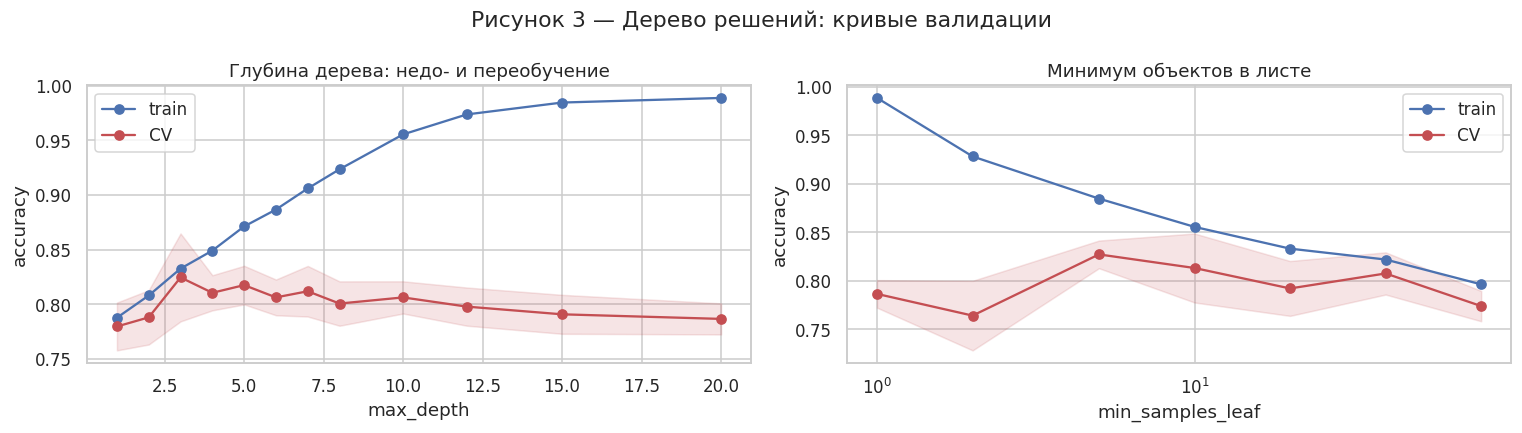

max_depth: {1: np.float64(0.78), 2: np.float64(0.788), 3: np.float64(0.824), 4: np.float64(0.81), 5: np.float64(0.817), 6: np.float64(0.806), 7: np.float64(0.812), 8: np.float64(0.801), 10: np.float64(0.806), 12: np.float64(0.798), 15: np.float64(0.791), 20: np.float64(0.786)}
train   : {1: np.float64(0.788), 2: np.float64(0.808), 3: np.float64(0.833), 4: np.float64(0.849), 5: np.float64(0.871), 6: np.float64(0.887), 7: np.float64(0.906), 8: np.float64(0.923), 10: np.float64(0.955), 12: np.float64(0.974), 15: np.float64(0.985), 20: np.float64(0.989)}
min_samples_leaf: {1: np.float64(0.786), 2: np.float64(0.764), 5: np.float64(0.827), 10: np.float64(0.813), 20: np.float64(0.792), 40: np.float64(0.808), 80: np.float64(0.774)}


In [13]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20]
tr, va = validation_curve(dt_pipe, X_train, y_train, param_name="clf__max_depth",
                          param_range=depths, cv=cv, scoring="accuracy")
leafs = [1, 2, 5, 10, 20, 40, 80]
tr2, va2 = validation_curve(dt_pipe, X_train, y_train, param_name="clf__min_samples_leaf",
                            param_range=leafs, cv=cv, scoring="accuracy")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, xs, a, b, lab in [(axes[0], depths, tr, va, "max_depth"), (axes[1], leafs, tr2, va2, "min_samples_leaf")]:
    ax.plot(xs, a.mean(1), "o-", label="train", color="#4C72B0")
    ax.plot(xs, b.mean(1), "o-", label="CV", color="#C44E52")
    ax.fill_between(xs, b.mean(1) - b.std(1), b.mean(1) + b.std(1), color="#C44E52", alpha=0.15)
    ax.set_xlabel(lab); ax.set_ylabel("accuracy"); ax.legend()
axes[1].set_xscale("log")
axes[0].set_title("Глубина дерева: недо- и переобучение"); axes[1].set_title("Минимум объектов в листе")
fig.suptitle("Рисунок 3 — Дерево решений: кривые валидации")
show(fig, "03_dt_curves")
print("max_depth:", dict(zip(depths, va.mean(1).round(3))))
print("train   :", dict(zip(depths, tr.mean(1).round(3))))
print("min_samples_leaf:", dict(zip(leafs, va2.mean(1).round(3))))

RESULTS["Дерево решений"] = dt_gs.best_estimator_
DEFAULT["Дерево решений"] = Pipeline([("prep", make_prep()), ("clf", DecisionTreeClassifier(random_state=SEED))]).fit(X_train, y_train)

**Комментарий к рисунку 3 — классическая картина недо- и переобучения.**

- **Глубина:** при `max_depth` = 1 (один вопрос — «мужчина ли это?») accuracy 0,78 и на train,
  и на CV — модель слишком простая (**недообучение**). Оптимум на CV при глубине 3 (0,824).
  Дальше точность на обучении растёт почти до 0,99 (глубина 20 — дерево запоминает каждого
  пассажира), а на CV падает до 0,786 — **переобучение**. Разрыв train–CV при глубине 20
  составляет 0,20.
- **Минимум объектов в листе:** при `min_samples_leaf` = 1 (дерево без ограничения глубины)
  CV 0,786; при 5 — 0,827. Требование «не меньше 5 пассажиров в листе» запрещает листья,
  построенные под одного-двух человек, — это регуляризация, альтернативная ограничению глубины.

**Таблица 4.** Лучшая комбинация: `criterion = gini`, `max_depth = 15`, `min_samples_leaf = 5`,
accuracy 0,827. Комбинации с глубиной 15, 10 и без ограничения при листе ≥ 5 практически
равноценны — **регуляризацию обеспечивает именно `min_samples_leaf`**, глубина при этом
не достигается. Мелкое дерево (глубина 3, gini) почти не уступает (0,825) и имеет **лучший
ROC-AUC** (0,862 против 0,848) — оно проще и устойчивее. Настройка дала самый большой эффект
среди всех методов: +4,1 п. п. accuracy и +0,07 ROC-AUC относительно дерева по умолчанию,
которое без ограничений переобучается.

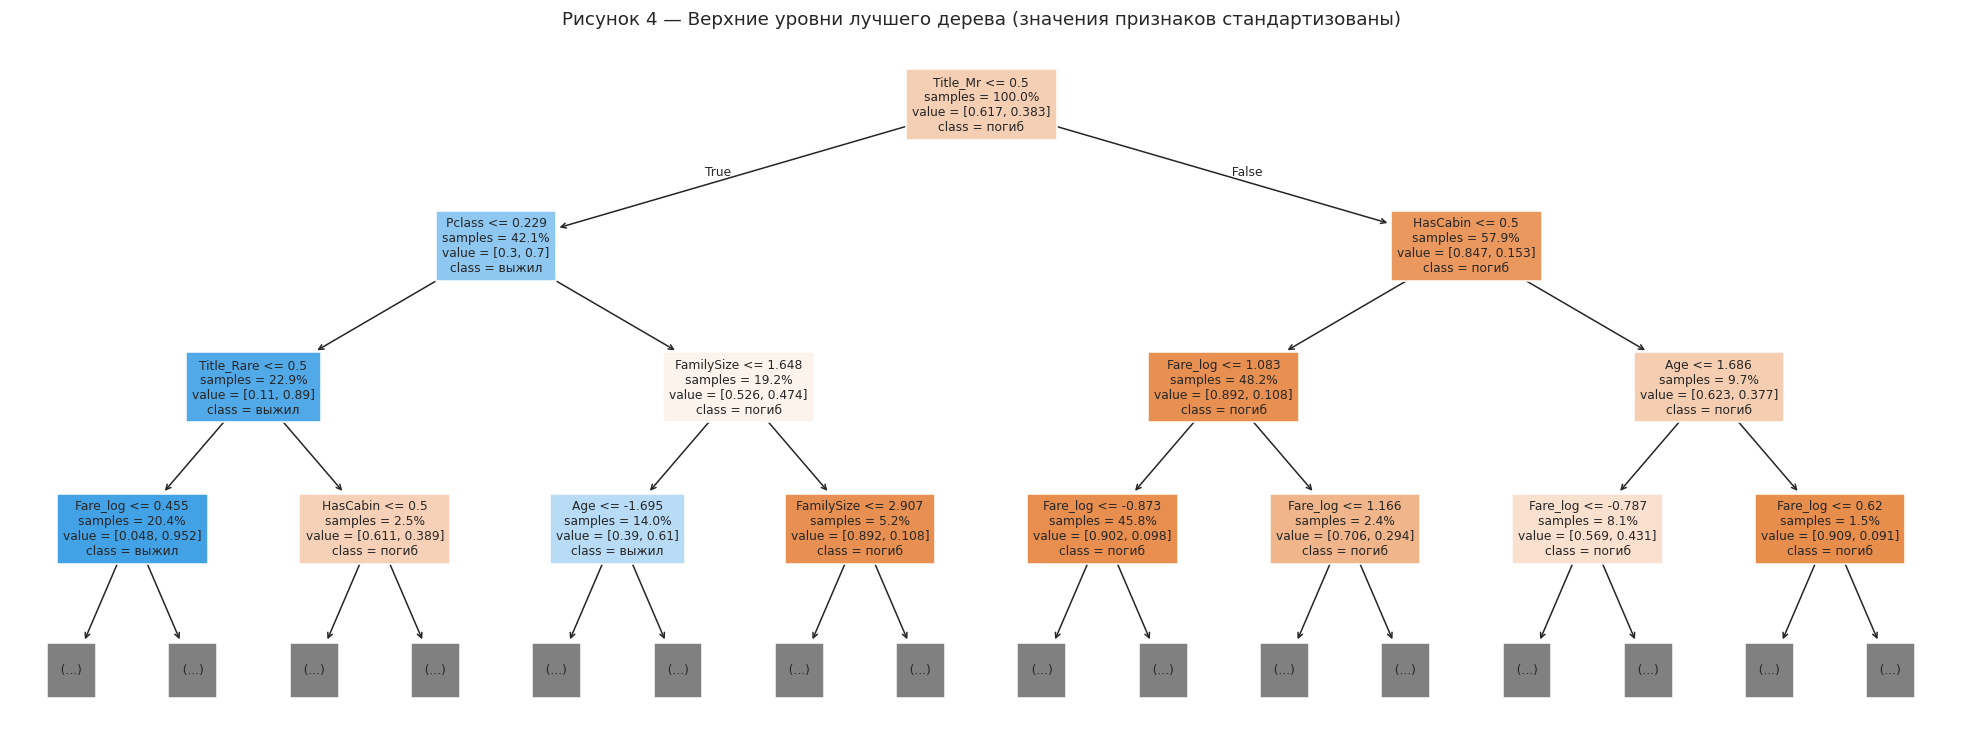

Важность признаков (снижение неоднородности):


,importance
Title_Mr,0.452
Fare_log,0.144
Pclass,0.112
Age,0.079
FamilySize,0.070
HasCabin,0.065
Title_Rare,0.044
Embarked_Q,0.013
Embarked_S,0.011
Title_Miss,0.007


In [14]:
best_dt = dt_gs.best_estimator_
names = feature_names(best_dt.named_steps["prep"])
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(best_dt.named_steps["clf"], feature_names=names, class_names=["погиб", "выжил"],
          filled=True, max_depth=3, fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title("Рисунок 4 — Верхние уровни лучшего дерева (значения признаков стандартизованы)")
show(fig, "04_tree")
imp = pd.Series(best_dt.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
print("Важность признаков (снижение неоднородности):")
imp[imp > 0].round(3).to_frame("importance")

**Комментарий к рисунку 4.** Первый вопрос дерева — `Title_Mr`: является ли пассажир взрослым
мужчиной. Он даёт наибольшее снижение неоднородности (важность 0,45 — почти половина всей
«работы» дерева).

- **Не взрослые мужчины** (женщины и мальчики, 42 % пассажиров, выжили 70 %) делятся по классу:
  в 1–2 классе выжили 89 %; в третьем — 47 %, и здесь решает **размер семьи**: в небольших семьях
  выжили 61 %, в больших — только 11 %.
- **Взрослые мужчины** (58 %, выжили 15 %) делятся по наличию каюты: без каюты выжили 11 %,
  с каютой — 38 %; дальше — по возрасту и стоимости билета.

Это ровно та логика, которую подсказывал разведочный анализ (рисунок 1): пол/возраст → класс →
семья. Признак `Sex_male` в списке
важности отсутствует: всю его информацию уже содержит `Title_Mr`, и дерево использует
только один из двух дублирующих признаков.

## 5.3. Линейный дискриминантный анализ

In [15]:
lda_pipe = Pipeline([("prep", make_prep()), ("clf", LinearDiscriminantAnalysis())])
lda_grid = [{"clf__solver": ["svd"]},
            {"clf__solver": ["lsqr", "eigen"], "clf__shrinkage": [None, "auto", 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]}]
lda_gs = tune(lda_pipe, lda_grid)
print("Лучшие параметры:", lda_gs.best_params_)
r = pd.DataFrame(lda_gs.cv_results_)
r["shrinkage"] = r["param_clf__shrinkage"].astype(str)
t = r[r.param_clf__solver.isin(["svd", "lsqr"])][["param_clf__solver", "shrinkage", "mean_test_accuracy",
                                                   "mean_test_f1", "mean_test_roc_auc"]]
print("Таблица 5 — LDA: решатель и сжатие ковариационной матрицы (lsqr; eigen даёт те же значения)")
t.columns = ["solver", "shrinkage", "CV accuracy", "CV f1", "CV roc_auc"]
t.round(4).reset_index(drop=True)

Лучшие параметры: {'clf__shrinkage': 0.01, 'clf__solver': 'lsqr'}
Таблица 5 — LDA: решатель и сжатие ковариационной матрицы (lsqr; eigen даёт те же значения)


,solver,shrinkage,CV accuracy,CV f1,CV roc_auc
0,svd,NaN,0.8216,0.7608,0.8743
1,lsqr,NaN,0.8216,0.7608,0.8742
2,lsqr,auto,0.8231,0.7651,0.8745
3,lsqr,0.01,0.8259,0.7678,0.8745
4,lsqr,0.05,0.8230,0.7653,0.8751
5,lsqr,0.1,0.8160,0.7573,0.8747
6,lsqr,0.2,0.8132,0.7555,0.8731
7,lsqr,0.3,0.8118,0.7562,0.8718
8,lsqr,0.5,0.8062,0.7463,0.8665
9,lsqr,0.7,0.7837,0.7102,0.8542


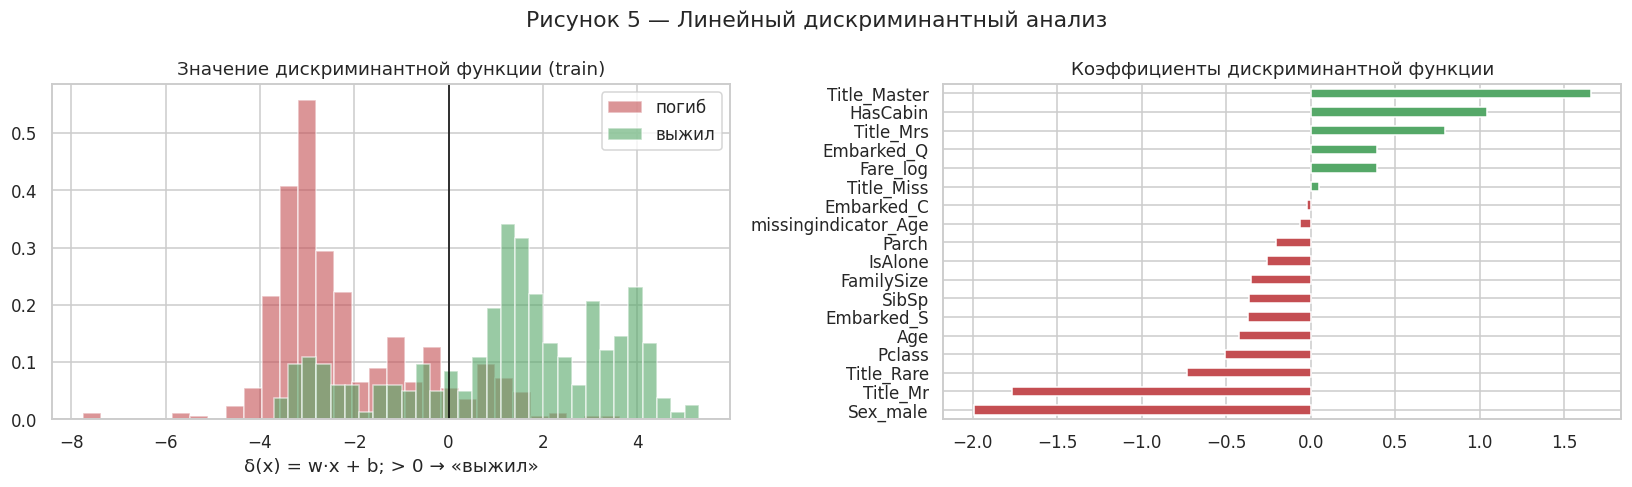

In [16]:
best_lda = lda_gs.best_estimator_
Z = best_lda.decision_function(X_train)            # значение дискриминантной функции = проекция на ось LD1
coef = pd.Series(best_lda.named_steps["clf"].coef_[0],
                 index=feature_names(best_lda.named_steps["prep"])).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for v, c, lab in [(0, "#C44E52", "погиб"), (1, "#55A868", "выжил")]:
    axes[0].hist(Z[y_train.values == v], bins=30, alpha=0.6, color=c, label=lab, density=True)
axes[0].set_title("Значение дискриминантной функции (train)"); axes[0].set_xlabel("δ(x) = w·x + b; > 0 → «выжил»")
axes[0].axvline(0, color="black", lw=1); axes[0].legend()
coef.plot(kind="barh", ax=axes[1], color=np.where(coef > 0, "#55A868", "#C44E52"))
axes[1].set_title("Коэффициенты дискриминантной функции")
fig.suptitle("Рисунок 5 — Линейный дискриминантный анализ")
show(fig, "05_lda")
RESULTS["LDA"] = best_lda
DEFAULT["LDA"] = Pipeline([("prep", make_prep()), ("clf", LinearDiscriminantAnalysis())]).fit(X_train, y_train)

**Таблица 5 и рисунок 5.**

- **Решатель:** `svd` и `lsqr` без сжатия дают одинаковый результат (accuracy 0,822) — это разные
  численные способы решить одну и ту же задачу. Отличие в том, что `svd` не вычисляет ковариационную
  матрицу явно и не поддерживает сжатие, а `lsqr` и `eigen` поддерживают.
- **Сжатие (shrinkage):** небольшое сжатие 0,01 даёт лучший результат (0,826), автоматический
  подбор Ледуа — Вольфа (`auto`) — 0,823. При сжатии > 0,1 качество падает, при 0,9 — до 0,757:
  ковариационная матрица заменяется почти диагональной, и LDA перестаёт учитывать связи между
  признаками. Слабый эффект сжатия объясняется тем, что выборка (712) велика по сравнению с числом
  признаков (18) — оценка ковариации и так устойчива.
- **Слева на рисунке 5** — распределение значения дискриминантной функции: классы сдвинуты друг
  относительно друга, но заметно перекрываются; граница δ = 0 проходит через область перекрытия.
  Это предел линейной модели на этих данных.
- **Справа** — коэффициенты (на стандартизованных признаках): сильнее всего снижают шансы
  `Sex_male` (−2,0) и `Title_Mr` (−1,75), затем `Title_Rare`, `Pclass`, `Age`; повышают —
  `Title_Master` (+1,65, мальчики), `HasCabin` (+1,0), `Title_Mrs`. Коэффициент `Title_Miss`
  почти нулевой — не потому, что обращение неважно, а потому, что информацию «женщина» уже несёт
  `Sex_male`. Пол и обращение сильно связаны, поэтому, как и в ЛР 1, отдельные коэффициенты
  при коррелированных признаках интерпретируются только вместе.

**Итог:** настройка почти ничего не дала (+0,4 п. п.) — у LDA мало параметров, а с параметрами
по умолчанию он уже даёт **лучший ROC-AUC среди всех методов** (0,874).

## 5.4. Метод опорных векторов

In [17]:
svm_pipe = Pipeline([("prep", make_prep()), ("clf", SVC(random_state=SEED))])
Cs = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
svm_grid = [{"clf__kernel": ["linear"], "clf__C": Cs},
            {"clf__kernel": ["rbf"], "clf__C": Cs, "clf__gamma": ["scale", 0.003, 0.01, 0.03, 0.1, 0.3, 1]},
            {"clf__kernel": ["poly"], "clf__C": [0.1, 1, 10], "clf__degree": [2, 3]}]
svm_gs = tune(svm_pipe, svm_grid)
print("Лучшие параметры:", svm_gs.best_params_)
r = pd.DataFrame(svm_gs.cv_results_)
best_by_kernel = r.loc[r.groupby("param_clf__kernel")["mean_test_accuracy"].idxmax(),
                       ["param_clf__kernel", "param_clf__C", "param_clf__gamma", "param_clf__degree",
                        "mean_test_accuracy", "mean_test_f1", "mean_test_roc_auc"]]
best_by_kernel.columns = ["kernel", "C", "gamma", "degree", "CV accuracy", "CV f1", "CV roc_auc"]
print("Таблица 6 — Лучшая комбинация для каждого ядра")
best_by_kernel.round(4).reset_index(drop=True)

Лучшие параметры: {'clf__C': 3, 'clf__gamma': 0.03, 'clf__kernel': 'rbf'}
Таблица 6 — Лучшая комбинация для каждого ядра


,kernel,C,gamma,degree,CV accuracy,CV f1,CV roc_auc
0,linear,1.0,NaN,NaN,0.8273,0.7631,0.8519
1,poly,1.0,NaN,2.0,0.8301,0.7690,0.8519
2,rbf,3.0,0.03,NaN,0.8315,0.7693,0.8570


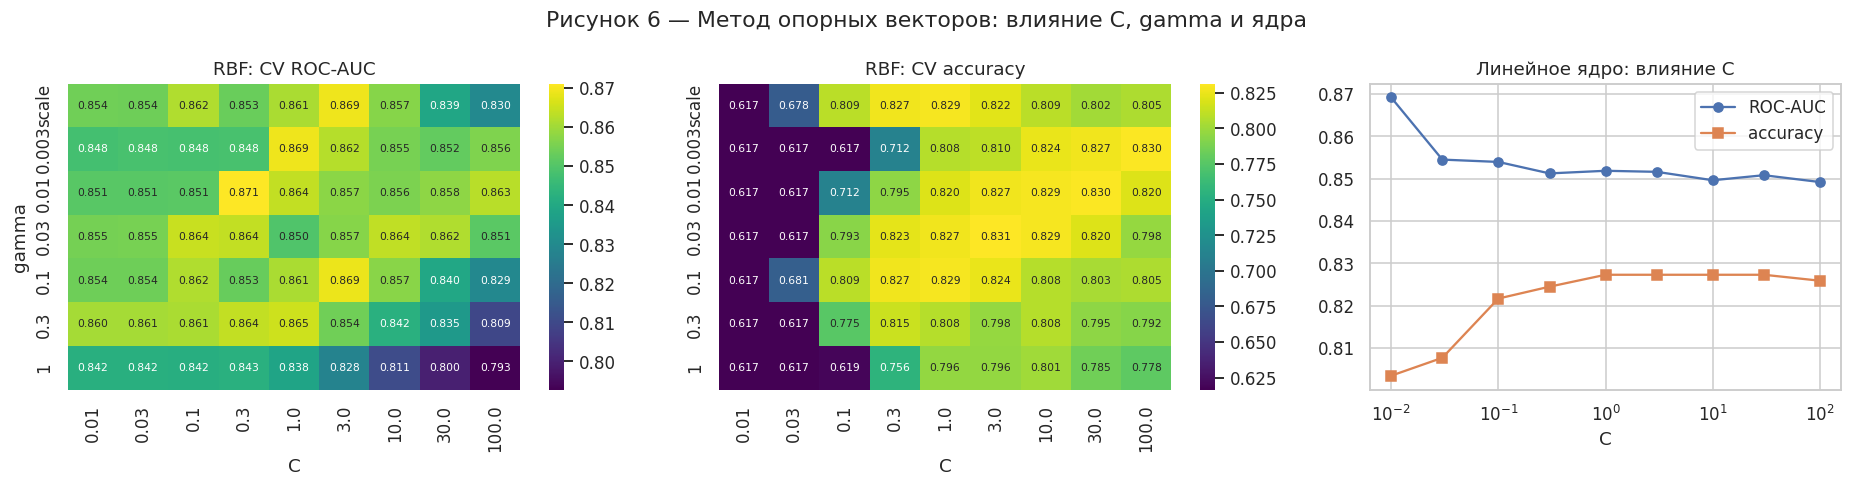

In [18]:
rb = r[r.param_clf__kernel == "rbf"]
piv = rb.pivot_table(index=rb.param_clf__gamma.astype(str), columns="param_clf__C", values="mean_test_roc_auc")
piv = piv.loc[["scale", "0.003", "0.01", "0.03", "0.1", "0.3", "1"]]
piv_acc = rb.pivot_table(index=rb.param_clf__gamma.astype(str), columns="param_clf__C",
                         values="mean_test_accuracy").loc[piv.index]
lin = r[r.param_clf__kernel == "linear"].sort_values("param_clf__C")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=axes[0], annot_kws={"size": 7})
axes[0].set_title("RBF: CV ROC-AUC"); axes[0].set_xlabel("C"); axes[0].set_ylabel("gamma")
sns.heatmap(piv_acc, annot=True, fmt=".3f", cmap="viridis", ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("RBF: CV accuracy"); axes[1].set_xlabel("C"); axes[1].set_ylabel("")
axes[2].semilogx(lin.param_clf__C.astype(float), lin.mean_test_roc_auc, "o-", label="ROC-AUC")
axes[2].semilogx(lin.param_clf__C.astype(float), lin.mean_test_accuracy, "s-", label="accuracy")
axes[2].set_title("Линейное ядро: влияние C"); axes[2].set_xlabel("C"); axes[2].legend()
fig.suptitle("Рисунок 6 — Метод опорных векторов: влияние C, gamma и ядра")
show(fig, "06_svm")
RESULTS["SVM"] = svm_gs.best_estimator_
DEFAULT["SVM"] = Pipeline([("prep", make_prep()), ("clf", SVC(random_state=SEED))]).fit(X_train, y_train)

**Комментарий к рисунку 6 и таблице 6.**

- **Ядро.** Лучшие варианты по CV accuracy (таблица 6): rbf — 0,832, полиномиальное 2-й степени —
  0,830, линейное — 0,827. Разница между ядрами всего 0,4 п. п.: после построения признаков
  (`Title`, `FamilySize`, `HasCabin`) классы почти линейно разделимы, и нелинейное ядро даёт лишь
  небольшую прибавку за счёт взаимодействий вроде «женщина × третий класс».
- **Линейное ядро (рисунок 6, справа):** с ростом C accuracy растёт с 0,803 до 0,827 и выходит
  на плато при C ≥ 1, а ROC-AUC, наоборот, максимален при самом малом C (0,869). Это та же
  ситуация, что описана в разделе 3: сильная регуляризация хорошо ранжирует пассажиров, но сдвигает
  порог решения.
- **Параметры RBF.** Тепловые карты показывают компромисс C и gamma. При **малом C** (0,01–0,03)
  модель настолько регуляризована, что почти всех относит к большему классу «погиб» — accuracy
  падает до уровня ≈ 0,62, хотя ROC-AUC остаётся высоким (ранжирование сохраняется, порог —
  нет; именно поэтому подбор по ROC-AUC выбирал плохую по accuracy модель). При **большом
  gamma** (1) и большом C модель обводит отдельные точки — переобучение, ROC-AUC падает.
  Оптимум — **C = 3, gamma = 0,03**: accuracy 0,832.
- Модель по умолчанию (C = 1, gamma = scale) была уже близка к оптимуму (0,829), поэтому выигрыш
  настройки мал (+0,3 п. п.).

## 5.5. Метод k ближайших соседей

Лучшие параметры: {'clf__n_neighbors': 12, 'clf__p': 1, 'clf__weights': 'uniform'}


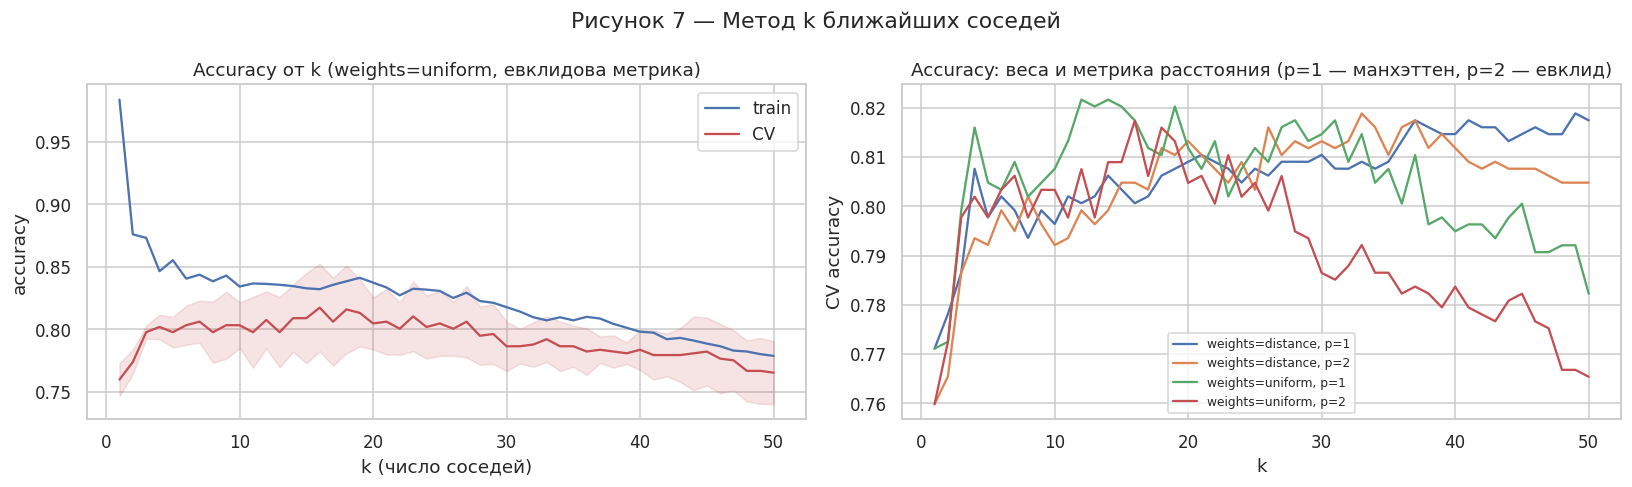

CV accuracy при k = {1: np.float64(0.76), 3: np.float64(0.798), 5: np.float64(0.798), 10: np.float64(0.803), 15: np.float64(0.809), 20: np.float64(0.805), 30: np.float64(0.786), 50: np.float64(0.765)}
train accuracy  k = {1: np.float64(0.984), 3: np.float64(0.873), 5: np.float64(0.855), 10: np.float64(0.834), 15: np.float64(0.833), 20: np.float64(0.837), 30: np.float64(0.818), 50: np.float64(0.779)}
Таблица 7 — kNN, топ-8 комбинаций


,n_neighbors,weights,p,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc,std_test_roc_auc
0,12,uniform,1,0.8217,0.8353,0.6703,0.7425,0.8574,0.0297
1,14,uniform,1,0.8216,0.8474,0.6556,0.7387,0.8571,0.0358
2,19,uniform,1,0.8203,0.8153,0.6958,0.7485,0.8651,0.0330
3,13,uniform,1,0.8203,0.8165,0.6886,0.7462,0.8579,0.0323
4,15,uniform,1,0.8203,0.8192,0.6848,0.7453,0.8619,0.0352
5,49,distance,1,0.8189,0.7841,0.7290,0.7553,0.8575,0.0251
6,33,distance,2,0.8188,0.7749,0.7436,0.7586,0.8522,0.0234
7,28,uniform,1,0.8175,0.8039,0.6997,0.7468,0.8691,0.0235


In [19]:
knn_pipe = Pipeline([("prep", make_prep()), ("clf", KNeighborsClassifier())])
knn_grid = {"clf__n_neighbors": list(range(1, 51)), "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}
knn_gs = tune(knn_pipe, knn_grid)
print("Лучшие параметры:", knn_gs.best_params_)
ks = list(range(1, 51))
tr, va = validation_curve(knn_pipe.set_params(clf__weights="uniform", clf__p=2), X_train, y_train,
                          param_name="clf__n_neighbors", param_range=ks, cv=cv, scoring="accuracy")
r = pd.DataFrame(knn_gs.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(ks, tr.mean(1), label="train", color="#4C72B0")
axes[0].plot(ks, va.mean(1), label="CV", color="#C44E52")
axes[0].fill_between(ks, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color="#C44E52", alpha=0.15)
axes[0].set_xlabel("k (число соседей)"); axes[0].set_ylabel("accuracy")
axes[0].set_title("Accuracy от k (weights=uniform, евклидова метрика)"); axes[0].legend()
for (w, p), g in r.groupby(["param_clf__weights", "param_clf__p"]):
    axes[1].plot(g.param_clf__n_neighbors, g.mean_test_accuracy, label=f"weights={w}, p={p}")
axes[1].set_xlabel("k"); axes[1].set_ylabel("CV accuracy"); axes[1].set_title("Accuracy: веса и метрика расстояния (p=1 — манхэттен, p=2 — евклид)")
axes[1].legend(fontsize=8)
fig.suptitle("Рисунок 7 — Метод k ближайших соседей")
show(fig, "07_knn")
print("CV accuracy при k =", {k: round(va.mean(1)[k - 1], 3) for k in [1, 3, 5, 10, 15, 20, 30, 50]})
print("train accuracy  k =", {k: round(tr.mean(1)[k - 1], 3) for k in [1, 3, 5, 10, 15, 20, 30, 50]})
print("Таблица 7 — kNN, топ-8 комбинаций")
RESULTS["kNN"] = knn_gs.best_estimator_
DEFAULT["kNN"] = Pipeline([("prep", make_prep()), ("clf", KNeighborsClassifier())]).fit(X_train, y_train)
results_table(knn_gs, ["clf__n_neighbors", "clf__weights", "clf__p"])

**Комментарий к рисунку 7.**

- **Число соседей k** — классический компромисс. При k = 1 accuracy на train 0,98 (каждый объект —
  сам себе сосед), а на CV — 0,76: **переобучение**, ответ определяется одним случайным соседом.
  С ростом k CV-качество растёт до 0,81 при k ≈ 15, а при k = 50 падает до 0,765 — **недообучение**:
  в голосовании участвует слишком широкая окрестность, локальная структура теряется.
- **Метрика расстояния:** при k = 10–20 манхэттенская (p = 1) лучше евклидовой (p = 2) на 1–1,5 п. п.
  (максимум 0,822 против 0,817). Она менее чувствительна к большому отклонению по одной координате,
  а для бинарных и one-hot признаков просто считает число несовпадений.
- **Веса:** при малых k варианты близки. При больших k `uniform` заметно деградирует (при k = 50:
  0,765–0,78), а `distance` держится на уровне 0,80–0,82: далёкие соседи получают малый вес,
  и широкая окрестность не «размывает» решение. Взвешивание по расстоянию делает kNN
  нечувствительным к завышенному k.

**Итог:** лучшая комбинация — **k = 12, uniform, манхэттенская метрика**, accuracy 0,822
(+2,4 п. п. к умолчанию k = 5, евклидова).

## 5.6. Итог настройки

In [20]:
rows = []
for name in RESULTS:
    d_cv, t_cv = cv_metrics(DEFAULT[name]), cv_metrics(RESULTS[name])
    rows.append({"метод": name, "CV ROC-AUC по умолч.": d_cv["roc_auc"], "CV ROC-AUC после": t_cv["roc_auc"],
                 "Δ ROC-AUC": t_cv["roc_auc"] - d_cv["roc_auc"],
                 "CV accuracy по умолч.": d_cv["accuracy"], "CV accuracy после": t_cv["accuracy"],
                 "Δ accuracy": t_cv["accuracy"] - d_cv["accuracy"]})
print("Таблица 8 — Эффект настройки гиперпараметров (5-fold CV на train)")
pd.DataFrame(rows).set_index("метод").round(4)

Таблица 8 — Эффект настройки гиперпараметров (5-fold CV на train)


,CV ROC-AUC по умолч.,CV ROC-AUC после,Δ ROC-AUC,CV accuracy по умолч.,CV accuracy после,Δ accuracy
метод,,,,,,
Наивный Байес,0.8630,0.8638,0.0008,0.8020,0.8132,0.0112
Дерево решений,0.7761,0.8476,0.0715,0.7865,0.8273,0.0408
LDA,0.8743,0.8745,0.0003,0.8216,0.8259,0.0042
SVM,0.8611,0.8570,-0.0041,0.8287,0.8315,0.0028
kNN,0.8371,0.8574,0.0202,0.7978,0.8217,0.0239


**Таблица 8.** Настройка повысила CV accuracy у всех методов, но эффект очень разный:

| Метод | Δ accuracy | Почему так |
|---|---|---|
| Дерево решений | **+4,1 п. п.** | по умолчанию дерево растёт без ограничений и переобучается; регуляризация (`min_samples_leaf`) — главное, что ему нужно |
| kNN | +2,4 п. п. | k = 5 слишком мало для шумных данных; манхэттенская метрика лучше для бинарных признаков |
| Наивный Байес | +1,1 п. п. | параметры только сглаживают оценки, предположение о независимости остаётся |
| LDA | +0,4 п. п. | параметров почти нет, модель по умолчанию уже оптимальна |
| SVM | +0,3 п. п. | значения по умолчанию (C = 1, gamma = scale) подобраны разработчиками sklearn удачно |

Чем гибче модель (дерево, kNN), тем сильнее она зависит от гиперпараметров; у моделей
с жёстким предположением о форме данных (LDA, наивный Байес) настройка почти ничего не меняет.

# 6. Нейронная сеть на TensorFlow

## 6.1. Архитектура и обучение

**Данные.** Та же предобработка (`make_prep`, обучена на train): 18 стандартизованных признаков.
Обучающая выборка разделена на train (569) и validation (143) со стратификацией.

**Базовая архитектура** — многослойный перцептрон (полносвязная сеть):

| Слой | Параметры | Назначение |
|---|---|---|
| Input | 18 признаков | вход |
| Dense | 32 нейрона, ReLU | первый скрытый слой |
| Dropout | 0,2 | случайно «выключает» 20 % нейронов на каждом шаге обучения — регуляризация |
| Dense | 16 нейронов, ReLU | второй скрытый слой |
| Dropout | 0,2 | |
| Dense | 1 нейрон, **sigmoid** | выход — вероятность класса «выжил» ∈ (0, 1) |

- **Функция активации ReLU** f(z) = max(0, z) — не насыщается при z > 0, градиент не затухает,
  вычисляется быстро. **Sigmoid** на выходе превращает число в вероятность.
- **Функция потерь — бинарная кросс-энтропия:** L = −[y·log p + (1 − y)·log(1 − p)]. Сильно штрафует
  уверенные ошибки (p → 0 при y = 1) и вместе с sigmoid даёт удобный градиент (p − y).
- **Оптимизатор Adam** (lr = 10⁻³) — стохастический градиентный спуск с адаптивным шагом для каждого
  веса и моментом; устойчив и почти не требует подбора.
- **Метрики:** accuracy и AUC на каждой эпохе.
- **Ранняя остановка** (`EarlyStopping`): обучение прекращается, если validation loss не улучшается
  20 эпох, и восстанавливаются веса лучшей эпохи.
- **TensorBoard:** callback пишет loss, accuracy и AUC на train и validation после каждой эпохи
  и гистограммы весов (`histogram_freq=1`) в папку `logs/fit/<эксперимент>/<запуск>`.

**Методика экспериментов.** Валидационная выборка маленькая (143 человека — один пассажир
= 0,7 п. п. accuracy), поэтому один запуск ненадёжен: результат зависит от случайной инициализации
весов. **Каждая конфигурация обучается с тремя seed** (42, 7, 2024), в таблицах — средние значения
на лучшей эпохе (минимум validation loss). Основной критерий — **validation loss**: он непрерывен
и чувствителен к уверенности модели, тогда как accuracy меняется скачками по 0,7 п. п.
В TensorBoard пишется запуск с seed 42.

In [21]:
# Для нейросети: предобработка обучается на train, из train выделяется валидационная выборка
prep_nn = make_prep().fit(X_train)
Xtr_all = prep_nn.transform(X_train).astype("float32")
Xte_nn = prep_nn.transform(X_test).astype("float32")
Xtr_nn, Xva_nn, ytr_nn, yva_nn = train_test_split(
    Xtr_all, y_train.values, test_size=0.2, stratify=y_train, random_state=SEED)
N_FEAT = Xtr_nn.shape[1]
print(f"train {Xtr_nn.shape}, validation {Xva_nn.shape}, test {Xte_nn.shape}; признаков {N_FEAT}")

LOGDIR = "logs/fit"
import shutil; shutil.rmtree("logs", ignore_errors=True)

def build_model(layers=(32, 16), activation="relu", dropout=0.2, lr=1e-3):
    """Полносвязная сеть для бинарной классификации."""
    model = keras.Sequential([keras.Input(shape=(N_FEAT,))])
    for units in layers:
        model.add(keras.layers.Dense(units, activation=activation))
        if dropout:
            model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(1, activation="sigmoid"))          # вероятность класса «выжил»
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

def run(exp, name, epochs=150, batch_size=32, early_stop=True, seed=SEED, log=True, **kw):
    """Обучает модель; seed=SEED пишет логи в TensorBoard (logs/fit/<эксперимент>/<запуск>)."""
    tf.keras.utils.set_random_seed(seed)
    model = build_model(**kw)
    cbs = []
    if log:
        safe = re.sub(r"[^\w.-]+", "_", name).strip("_")   # имя папки без пробелов, «:» и «=» (Windows)
        cbs.append(keras.callbacks.TensorBoard(log_dir=f"{LOGDIR}/{exp}/{safe}", histogram_freq=1))
    if early_stop:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True))
    h = model.fit(Xtr_nn, ytr_nn, validation_data=(Xva_nn, yva_nn), epochs=epochs,
                  batch_size=batch_size, callbacks=cbs, verbose=0)
    hist = pd.DataFrame(h.history)
    best = int(hist.val_loss.idxmin())
    return model, hist, {"эксперимент": exp, "запуск": name, "эпох обучено": len(hist),
                         "лучшая эпоха": best + 1, "val_loss": hist.val_loss[best],
                         "val_accuracy": hist.val_accuracy[best], "val_auc": hist.val_auc[best],
                         "train_accuracy": hist.accuracy[best]}

def experiment(exp, configs, seeds=(42, 7, 2024)):
    """Каждую конфигурацию обучаем с 3 seed: валидация маленькая (143 чел.), одного запуска мало."""
    rows, hists = [], {}
    for name, kw in configs.items():
        runs = []
        for s in seeds:
            m, h, r = run(exp, name, seed=s, log=(s == seeds[0]), **kw)
            runs.append(r)
            if s == seeds[0]:
                hists[name] = h
        rr = pd.DataFrame(runs)
        rows.append({"запуск": name, "эпох (медиана)": int(rr["эпох обучено"].median()),
                     "лучшая эпоха (медиана)": int(rr["лучшая эпоха"].median()),
                     "val_loss": rr.val_loss.mean(), "val_accuracy": rr.val_accuracy.mean(),
                     "val_acc std": rr.val_accuracy.std(), "val_auc": rr.val_auc.mean(),
                     "train_accuracy": rr.train_accuracy.mean()})
    return pd.DataFrame(rows).set_index("запуск"), hists

def plot_hists(hists, title, name, metric="loss"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
    colors = sns.color_palette("tab10", len(hists))
    for (n, h), c in zip(hists.items(), colors):
        axes[0].plot(h["loss"], color=c, ls="--", lw=1)
        axes[0].plot(h["val_loss"], color=c, lw=1.6, label=n)
        axes[1].plot(h["accuracy"], color=c, ls="--", lw=1)
        axes[1].plot(h["val_accuracy"], color=c, lw=1.6, label=n)
    axes[0].set_title("loss (пунктир — train, сплошная — validation)"); axes[0].set_xlabel("эпоха")
    axes[1].set_title("accuracy (пунктир — train, сплошная — validation)"); axes[1].set_xlabel("эпоха")
    axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
    fig.suptitle(title)
    show(fig, name)

base = build_model()
base.summary()

train (569, 18), validation (143, 18), test (179, 18); признаков 18


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

Сеть имеет 1 153 обучаемых параметра: 18·32 + 32 = 608 в первом слое, 32·16 + 16 = 528 во втором
и 16 + 1 = 17 в выходном. Это немного относительно 569 обучающих примеров, но достаточно, чтобы
переобучиться — это и покажет первый эксперимент.

## 6.2. Эксперимент 1: число эпох

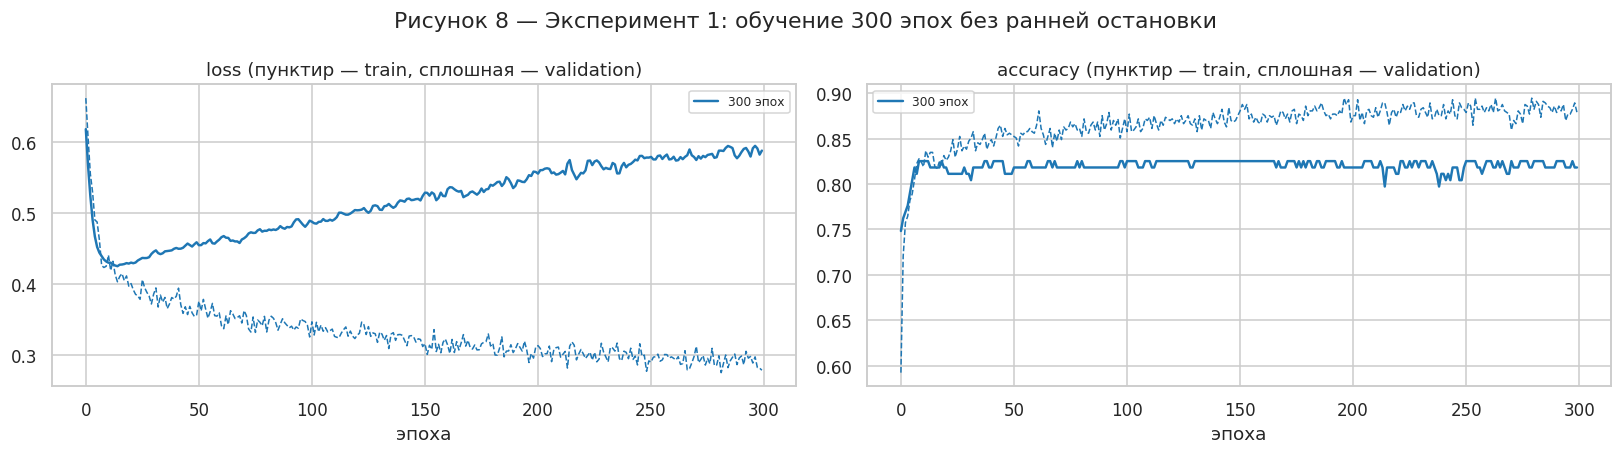

эпоха  10: train loss 0.425 acc 0.824 | val loss 0.432 acc 0.825
эпоха  25: train loss 0.378 acc 0.830 | val loss 0.435 acc 0.811
эпоха  50: train loss 0.356 acc 0.854 | val loss 0.459 acc 0.811
эпоха  15: train loss 0.403 acc 0.835 | val loss 0.425 acc 0.818
эпоха 100: train loss 0.325 acc 0.872 | val loss 0.489 acc 0.818
эпоха 200: train loss 0.311 acc 0.868 | val loss 0.558 acc 0.818
эпоха 300: train loss 0.279 acc 0.879 | val loss 0.588 acc 0.818

Минимум val_loss на эпохе 15


In [22]:
# Эксперимент 1. Число эпох: 300 эпох БЕЗ ранней остановки
m300, h300, r300 = run("1_epochs", "300_epochs_no_ES", epochs=300, early_stop=False)
plot_hists({"300 эпох": h300}, "Рисунок 8 — Эксперимент 1: обучение 300 эпох без ранней остановки", "08_nn_epochs")
best_ep = int(h300.val_loss.idxmin())
for e in [10, 25, 50, best_ep + 1, 100, 200, 300]:
    print(f"эпоха {e:3d}: train loss {h300.loss[e-1]:.3f} acc {h300.accuracy[e-1]:.3f} | "
          f"val loss {h300.val_loss[e-1]:.3f} acc {h300.val_accuracy[e-1]:.3f}")
print(f"\nМинимум val_loss на эпохе {best_ep + 1}")

**Комментарий к рисунку 8.** Сеть обучалась 300 эпох без ранней остановки.

- **Эпохи 1–15:** обе кривые loss быстро падают — сеть учит основные закономерности. Минимум
  validation loss (≈ 0,425) достигается на **15-й эпохе**, accuracy на валидации 0,818.
- **Эпохи 15–300:** train loss продолжает снижаться (0,40 → 0,28), train accuracy растёт до 0,88,
  а validation loss **растёт** с 0,43 до 0,59. Это **переобучение**: сеть запоминает обучающих
  пассажиров. Validation accuracy при этом почти не меняется (0,81–0,82) — модель по-прежнему
  относит большинство к верному классу, но становится **чрезмерно уверенной** в ошибочных
  ответах, что и видит кросс-энтропия.

**Вывод:** оптимальное число эпох — порядка 15–20; больше эпох вредят. Поэтому в остальных
экспериментах используется **ранняя остановка** с восстановлением лучших весов — число эпох
перестаёт быть параметром, который надо угадывать.

## 6.3. Эксперимент 2: размер батча

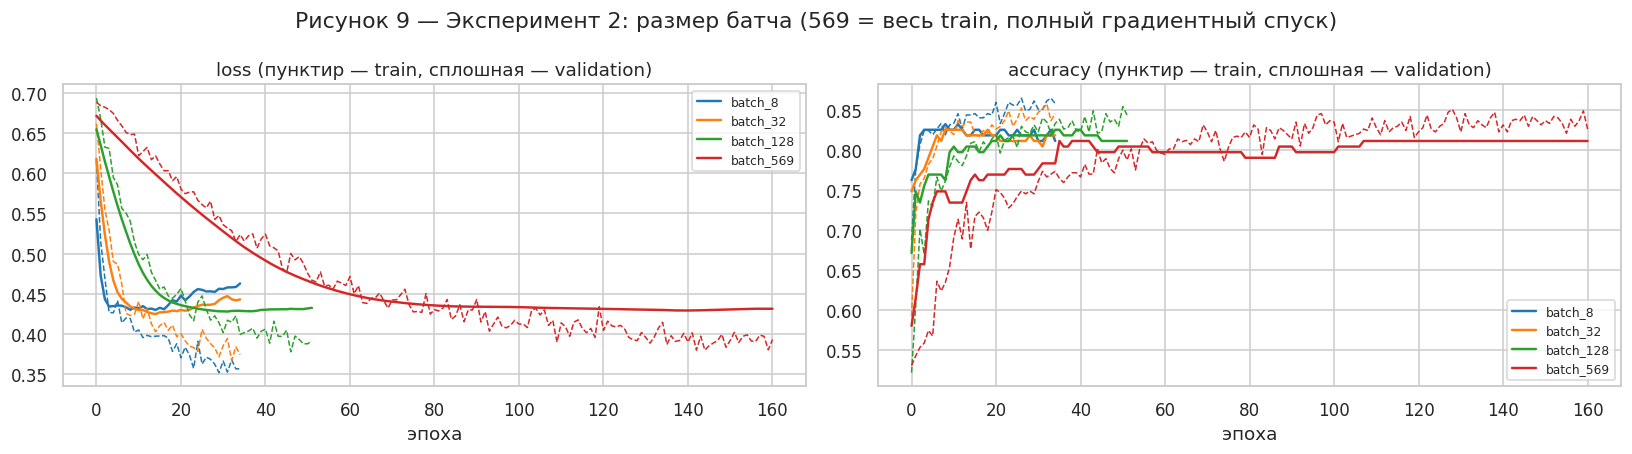

Таблица 9 — Размер батча (среднее по 3 seed, метрики на лучшей эпохе)


,эпох (медиана),лучшая эпоха (медиана),val_loss,val_accuracy,val_acc std,val_auc,train_accuracy
запуск,,,,,,,
batch_8,35,15,0.4325,0.8252,0.0070,0.8640,0.8407
batch_32,40,20,0.4283,0.8205,0.0040,0.8709,0.8412
batch_128,79,59,0.4299,0.8252,0.0121,0.8703,0.8401
batch_569,171,151,0.4325,0.8159,0.0040,0.8672,0.8313


In [23]:
# Эксперимент 2. Размер батча (архитектура 32-16, relu, ранняя остановка)
res_batch, h_batch = experiment("2_batch", {f"batch_{b}": {"batch_size": b, "epochs": 300} for b in [8, 32, 128, 569]})
plot_hists(h_batch, "Рисунок 9 — Эксперимент 2: размер батча (569 = весь train, полный градиентный спуск)", "09_nn_batch")
print("Таблица 9 — Размер батча (среднее по 3 seed, метрики на лучшей эпохе)")
res_batch.round(4)

**Комментарий к рисунку 9 и таблице 9.** Размер батча — сколько примеров используется для одного
шага градиентного спуска; за эпоху делается 569 / batch шагов.

- **batch = 8** (72 шага за эпоху): быстрое, но шумное обучение — лучшая эпоха уже 15-я,
  кривые «дрожат».
- **batch = 32** (18 шагов): лучшая эпоха 20-я, **минимальный validation loss** (0,428).
- **batch = 128** (5 шагов): обучение медленнее, лучшая эпоха 59-я; качество то же.
- **batch = 569** (весь train, 1 шаг за эпоху — полный, не стохастический градиентный спуск):
  нужно 151 эпоха, качество немного хуже (val accuracy 0,816).

**Вывод:** размер батча меняет **скорость сходимости в эпохах** (15 → 151), но почти не меняет
итоговое качество (val loss 0,428–0,433, разница меньше одного пассажира). Маленький батч вносит
шум в градиент, который работает как регуляризация; большой — даёт точный, но медленный спуск.
Выбран **batch = 32** как оптимум по val loss и скорости.

## 6.4. Эксперимент 3: число слоёв и нейронов

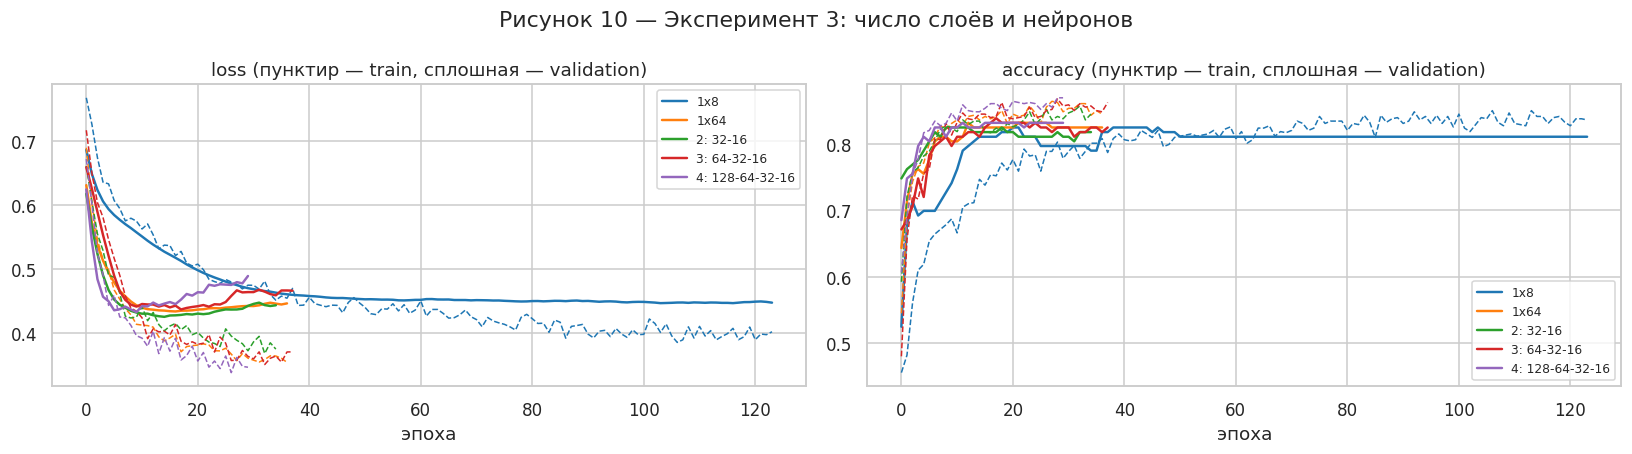

Таблица 10 — Архитектура (среднее по 3 seed)


,эпох (медиана),лучшая эпоха (медиана),val_loss,val_accuracy,val_acc std,val_auc,train_accuracy,параметров
запуск,,,,,,,,
1x8,106,86,0.4341,0.8135,0.0107,0.8690,0.8260,161
1x64,37,17,0.4429,0.8252,0.0070,0.8647,0.8424,1281
2: 32-16,40,20,0.4283,0.8205,0.0040,0.8709,0.8412,1153
3: 64-32-16,38,18,0.4392,0.8345,0.0081,0.8651,0.8360,3841
4: 128-64-32-16,30,10,0.4377,0.8298,0.0040,0.8621,0.8389,13313


In [24]:
# Эксперимент 3. Число слоёв и нейронов
arch = {"1x8": (8,), "1x64": (64,), "2: 32-16": (32, 16), "3: 64-32-16": (64, 32, 16), "4: 128-64-32-16": (128, 64, 32, 16)}
res_arch, h_arch = experiment("3_layers", {k: {"layers": v} for k, v in arch.items()})
plot_hists(h_arch, "Рисунок 10 — Эксперимент 3: число слоёв и нейронов", "10_nn_layers")
res_arch["параметров"] = [build_model(layers=v).count_params() for v in arch.values()]
print("Таблица 10 — Архитектура (среднее по 3 seed)")
res_arch.round(4)

**Комментарий к рисунку 10 и таблице 10.**

- **1 слой × 8 нейронов** (161 параметр): самая простая сеть учится медленно (лучшая эпоха 86)
  и даёт наименьшую val accuracy (0,814) — ей не хватает ёмкости (лёгкое **недообучение**).
- **1 × 64** и **2 слоя 32-16**: лучший validation loss у 32-16 (0,428).
- **3 слоя 64-32-16** (3 841 параметр): **лучшая val accuracy** (0,835), но val loss выше (0,439).
- **4 слоя 128-64-32-16** (13 313 параметров): переобучение начинается уже после 10-й эпохи —
  ёмкости слишком много для 569 примеров.

**Вывод:** глубина выше 2–3 слоёв не нужна — данные табличные, признаков 18, зависимости простые.
Разброс val accuracy между архитектурами (0,814–0,835) — это 3 пассажира из 143, то есть на грани
случайности. Выбрана **2 слоя 32-16** как лучшая по val loss при минимальной сложности.

## 6.5. Эксперимент 4: функции активации

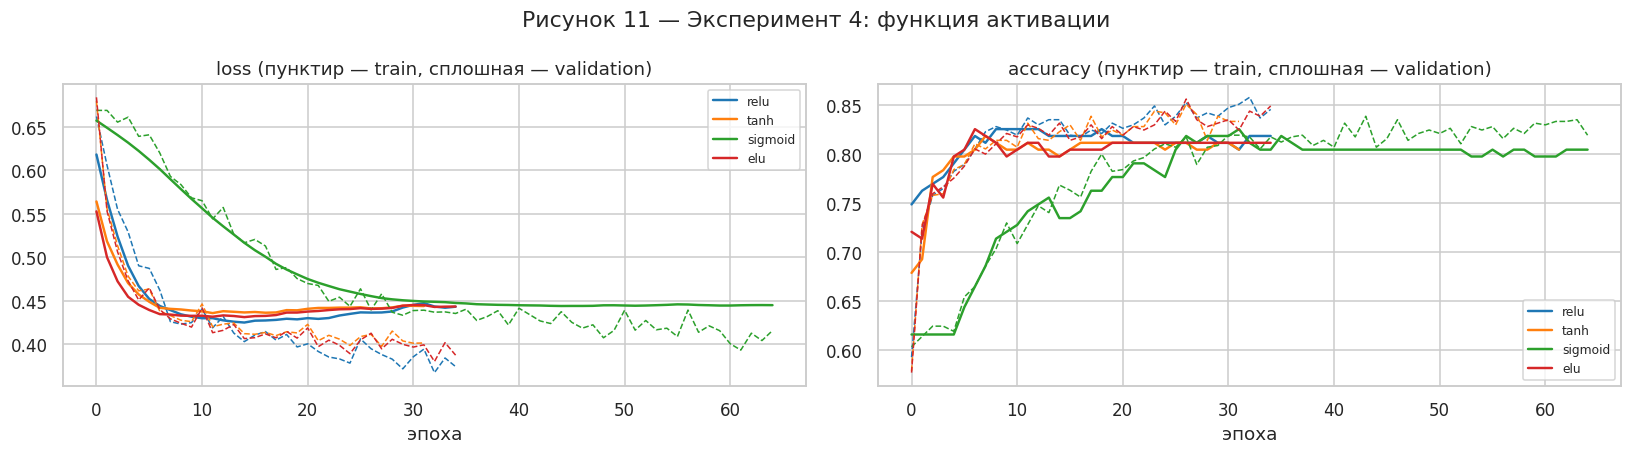

Таблица 11 — Функция активации (среднее по 3 seed)


,эпох (медиана),лучшая эпоха (медиана),val_loss,val_accuracy,val_acc std,val_auc,train_accuracy
запуск,,,,,,,
relu,40,20,0.4283,0.8205,0.0040,0.8709,0.8412
tanh,34,14,0.4386,0.8159,0.0081,0.8729,0.8325
sigmoid,100,80,0.4415,0.8135,0.0081,0.8721,0.8178
elu,34,14,0.4306,0.8042,0.0070,0.8757,0.8243


In [25]:
# Эксперимент 4. Функции активации скрытых слоёв (архитектура 32-16)
res_act, h_act = experiment("4_activation", {a: {"activation": a} for a in ["relu", "tanh", "sigmoid", "elu"]})
plot_hists(h_act, "Рисунок 11 — Эксперимент 4: функция активации", "11_nn_activation")
print("Таблица 11 — Функция активации (среднее по 3 seed)")
res_act.round(4)

**Комментарий к рисунку 11 и таблице 11.**

- **ReLU** — лучший validation loss (0,428) и val accuracy 0,821.
- **tanh** и **ELU** сходятся быстрее (лучшая эпоха 14), имеют чуть более высокий val AUC
  (0,873–0,876), но val loss выше; у ELU самая низкая val accuracy (0,804).
- **Sigmoid** в скрытых слоях учится **в 4–5 раз медленнее** (лучшая эпоха 80 против 14–20):
  её производная не больше 0,25 и стремится к нулю при больших |z| — градиент затухает, проходя
  через слои. Итоговое качество при этом сравнимо — сеть мелкая, затухание не успевает стать
  критичным.

**Вывод:** на мелкой сети выбор активации влияет в первую очередь на **скорость** обучения,
а не на итоговое качество. Выбрана **ReLU**.

## 6.6. Эксперимент 5 (дополнительно): скорость обучения и Dropout

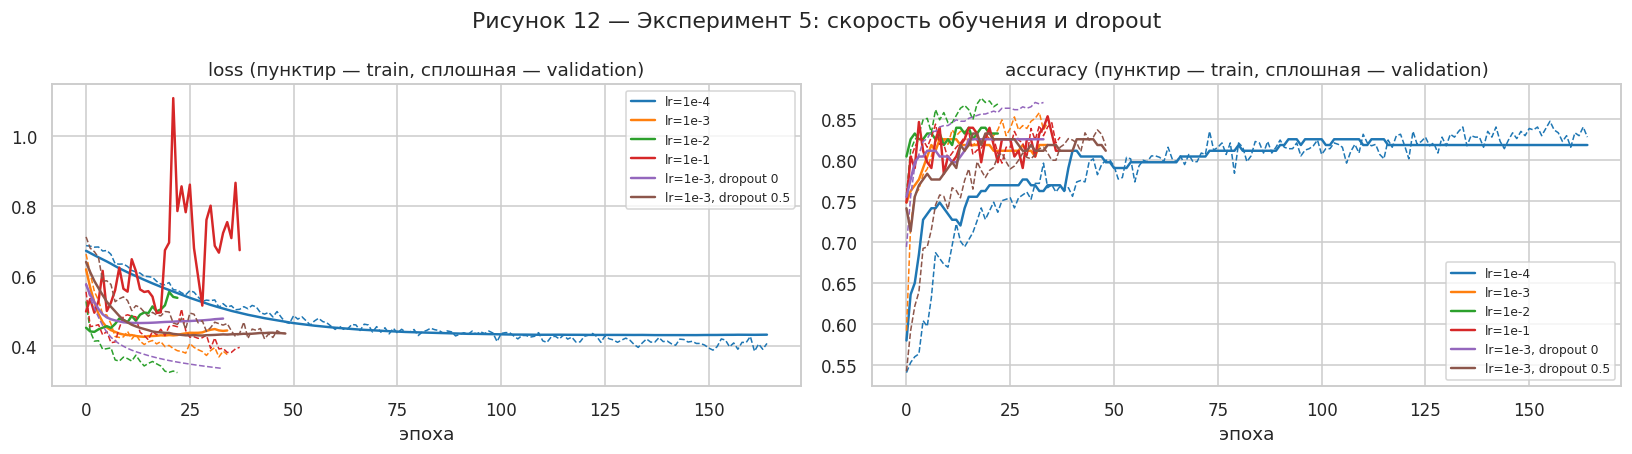

Таблица 12 — Скорость обучения и dropout (среднее по 3 seed)


,эпох (медиана),лучшая эпоха (медиана),val_loss,val_accuracy,val_acc std,val_auc,train_accuracy
запуск,,,,,,,
lr=1e-4,238,218,0.4300,0.8182,0.0000,0.8690,0.8360
lr=1e-3,40,20,0.4283,0.8205,0.0040,0.8709,0.8412
lr=1e-2,23,3,0.4384,0.8205,0.0107,0.8648,0.8213
lr=1e-1,22,2,0.4711,0.8112,0.0252,0.8572,0.7885
"lr=1e-3, dropout 0",34,14,0.4543,0.8182,0.0140,0.8499,0.8530
"lr=1e-3, dropout 0.5",69,49,0.4256,0.8205,0.0081,0.8748,0.8120


In [26]:
# Эксперимент 5 (дополнительно). Скорость обучения Adam и Dropout
res_lr, h_lr = experiment("5_lr_dropout", {
    "lr=1e-4": {"lr": 1e-4, "epochs": 400}, "lr=1e-3": {"lr": 1e-3}, "lr=1e-2": {"lr": 1e-2},
    "lr=1e-1": {"lr": 1e-1}, "lr=1e-3, dropout 0": {"lr": 1e-3, "dropout": 0.0},
    "lr=1e-3, dropout 0.5": {"lr": 1e-3, "dropout": 0.5}})
plot_hists(h_lr, "Рисунок 12 — Эксперимент 5: скорость обучения и dropout", "12_nn_lr")
print("Таблица 12 — Скорость обучения и dropout (среднее по 3 seed)")
res_lr.round(4)

**Комментарий к рисунку 12 и таблице 12.**

- **lr = 10⁻⁴** — слишком маленький шаг: до минимума нужно 218 эпох, качество то же.
- **lr = 10⁻³** (по умолчанию Adam) — оптимум.
- **lr = 10⁻²** — минимум уже на 3-й эпохе, дальше сеть быстро переобучается.
- **lr = 10⁻¹** — шаг слишком большой: обучение нестабильно (val accuracy 0,811 ± 0,025 —
  в 3–6 раз больший разброс между seed), train accuracy на лучшей эпохе всего 0,79.
- **Dropout:** без dropout val loss хуже всех (0,454) — разрыв train/val максимален
  (train accuracy 0,853), сеть переобучается. **Dropout 0,5 даёт лучший val loss всех
  экспериментов (0,426) и лучший val AUC (0,875)** — сильная регуляризация полезна на маленьком
  датасете.

## 6.7. Итоговая сеть

In [27]:
# Итоговая конфигурация выбирается по val_loss (среднее по 3 seed) из всех экспериментов
all_nn = pd.concat([res_batch.assign(exp="batch"), res_arch.drop(columns="параметров").assign(exp="layers"),
                    res_act.assign(exp="activation"), res_lr.assign(exp="lr/dropout")])
print("Топ-5 конфигураций по val_loss:")
print(all_nn.sort_values("val_loss").head(5)[["exp", "val_loss", "val_accuracy", "val_auc"]].round(4).to_string())

Топ-5 конфигураций по val_loss:
                             exp  val_loss  val_accuracy  val_auc
запуск                                                           
lr=1e-3, dropout 0.5  lr/dropout    0.4256        0.8205   0.8748
batch_32                   batch    0.4283        0.8205   0.8709
lr=1e-3               lr/dropout    0.4283        0.8205   0.8709
2: 32-16                  layers    0.4283        0.8205   0.8709
relu                  activation    0.4283        0.8205   0.8709


По сумме экспериментов итоговая конфигурация: **2 скрытых слоя 32-16, ReLU, Dropout 0,5, Adam
lr = 10⁻³, batch = 32, ранняя остановка** (patience 20). Это лучшая по validation loss
конфигурация; все параметры, кроме dropout, совпадают с базовыми, так как именно они оказались
лучшими в своих экспериментах.

In [28]:
FINAL_CFG = dict(layers=(32, 16), activation="relu", dropout=0.5, lr=1e-3, batch_size=32)   # лучшая по val_loss
nn_model, nn_hist, nn_row = run("6_final", "final", epochs=300, **FINAL_CFG)
print(f"Итоговая сеть: {FINAL_CFG}, обучено эпох: {nn_row['эпох обучено']}, лучшая эпоха: {nn_row['лучшая эпоха']}")

class KerasWrap:
    """Обёртка, чтобы сеть оценивалась теми же функциями, что и модели sklearn."""
    def __init__(self, m, prep): self.m, self.prep = m, prep
    def predict_proba(self, X):
        p = self.m.predict(self.prep.transform(X).astype("float32"), verbose=0).ravel()
        return np.c_[1 - p, p]
    def predict(self, X): return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

RESULTS["Нейросеть (TF)"] = KerasWrap(nn_model, prep_nn)
pd.Series(test_metrics(RESULTS["Нейросеть (TF)"])).round(4).to_frame("test")

Итоговая сеть: {'layers': (32, 16), 'activation': 'relu', 'dropout': 0.5, 'lr': 0.001, 'batch_size': 32}, обучено эпох: 49, лучшая эпоха: 29


,test
accuracy,0.7989
precision,0.7895
recall,0.6522
f1,0.7143
roc_auc,0.8502


Итоговая сеть остановилась на 49-й эпохе, лучшие веса — с 29-й. **На тесте:** accuracy 0,799,
precision 0,789, recall 0,652, F1 0,714, ROC-AUC 0,850.

Это немного ниже валидационной точности (0,82) — разница 2 п. п., около 4 пассажиров из 179,
в пределах случайного разброса. Важнее то, что **нейросеть не превзошла классические методы**
(LDA и SVM — 0,832, см. раздел 7). Причины:

1. **Мало данных:** нейросети раскрывают преимущество на десятках тысяч примеров и на сырых
   неструктурированных данных (изображения, текст). Здесь 569 обучающих примеров — а ещё 143
   пришлось отдать на валидацию для ранней остановки, тогда как модели sklearn обучались на всех 712.
2. **Признаки уже построены вручную:** `Title`, `FamilySize`, `HasCabin` содержат взаимодействия,
   которые сеть могла бы выучить сама. После этого классы почти линейно разделимы, и скрытым слоям
   нечего добавить к линейной модели.
3. **Дисперсия обучения:** результат зависит от инициализации весов (разброс val accuracy между seed
   до 2,5 п. п.) — для такого маленького датасета это сопоставимо с разницей между методами.

## 6.8. Мониторинг обучения в TensorBoard

Callback `keras.callbacks.TensorBoard` записывает в `logs/fit` по каждому запуску: скаляры
`epoch_loss`, `epoch_accuracy`, `epoch_auc` для train и validation, гистограммы и распределения
весов каждого слоя, граф модели. Запуск: `tensorboard --logdir logs/fit` → http://localhost:6006.

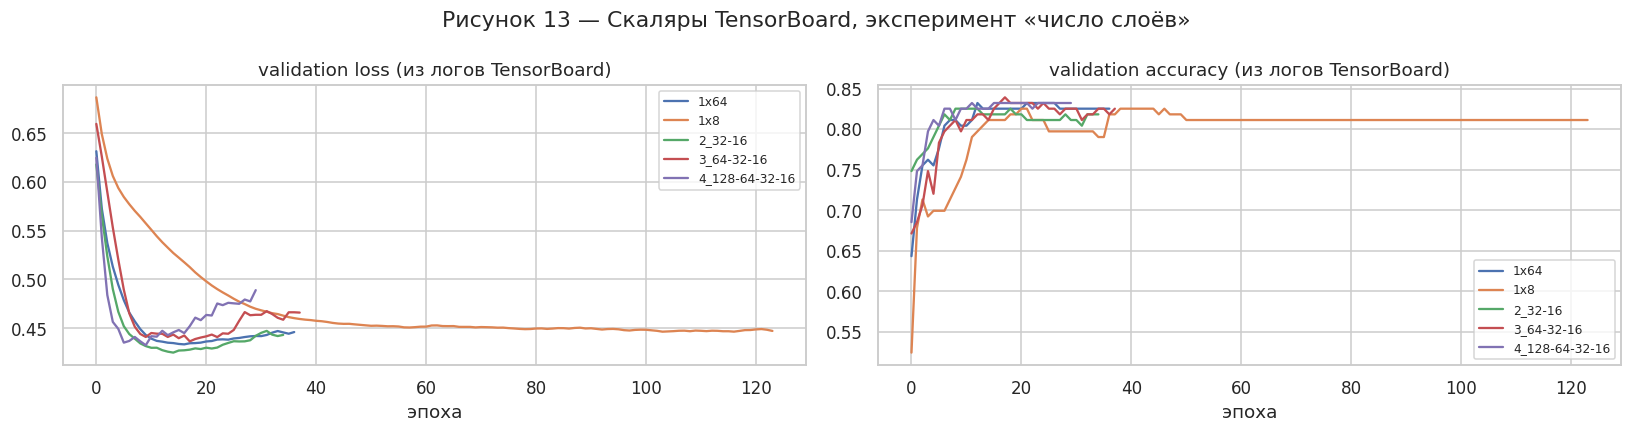

Структура логов TensorBoard:
   logs/fit/1_epochs/300_epochs_no_ES
   logs/fit/2_batch/batch_128
   logs/fit/2_batch/batch_32
   logs/fit/2_batch/batch_569
   logs/fit/2_batch/batch_8
   logs/fit/3_layers/1x64
   logs/fit/3_layers/1x8
   logs/fit/3_layers/2_32-16
   logs/fit/3_layers/3_64-32-16
   logs/fit/3_layers/4_128-64-32-16
   logs/fit/4_activation/elu
   logs/fit/4_activation/relu
   logs/fit/4_activation/sigmoid
   logs/fit/4_activation/tanh
   logs/fit/5_lr_dropout/lr_1e-1
   logs/fit/5_lr_dropout/lr_1e-2
   logs/fit/5_lr_dropout/lr_1e-3
   logs/fit/5_lr_dropout/lr_1e-3_dropout_0
   logs/fit/5_lr_dropout/lr_1e-3_dropout_0.5
   logs/fit/5_lr_dropout/lr_1e-4
   logs/fit/6_final/final


In [29]:
# Скаляры, записанные callback-ом TensorBoard, читаются из event-файлов — это те же графики,
# что показывает TensorBoard во вкладке Scalars (здесь — для эксперимента «размер батча»).
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

def tb_scalars(run_dir, split, tag="epoch_loss"):
    ea = EventAccumulator(os.path.join(run_dir, split), size_guidance={"tensors": 0}).Reload()
    return pd.Series({e.step: float(tf.make_ndarray(e.tensor_proto)) for e in ea.Tensors(tag)})

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for run_dir in sorted(glob.glob(f"{LOGDIR}/3_layers/*")):
    n = os.path.basename(run_dir)
    axes[0].plot(tb_scalars(run_dir, "validation", "epoch_loss"), label=n)
    axes[1].plot(tb_scalars(run_dir, "validation", "epoch_accuracy"), label=n)
axes[0].set_title("validation loss (из логов TensorBoard)"); axes[1].set_title("validation accuracy (из логов TensorBoard)")
for a in axes: a.set_xlabel("эпоха"); a.legend(fontsize=8)
fig.suptitle("Рисунок 13 — Скаляры TensorBoard, эксперимент «число слоёв»")
show(fig, "13_tb_scalars")

print("Структура логов TensorBoard:")
for d in sorted(glob.glob(f"{LOGDIR}/*/*")):
    print("  ", d)

**Интерактивный TensorBoard прямо в Jupyter** (работает при запуске ноутбука в Jupyter / VS Code;
в статичном просмотре, например на GitHub, не отображается — поэтому ниже приведены снимки экрана):

```python
%load_ext tensorboard
%tensorboard --logdir logs/fit
```

Вне Jupyter: `tensorboard --logdir logs/fit`, затем открыть http://localhost:6006.

Рисунок 14 — TensorBoard, вкладка Scalars: эксперимент «размер батча»


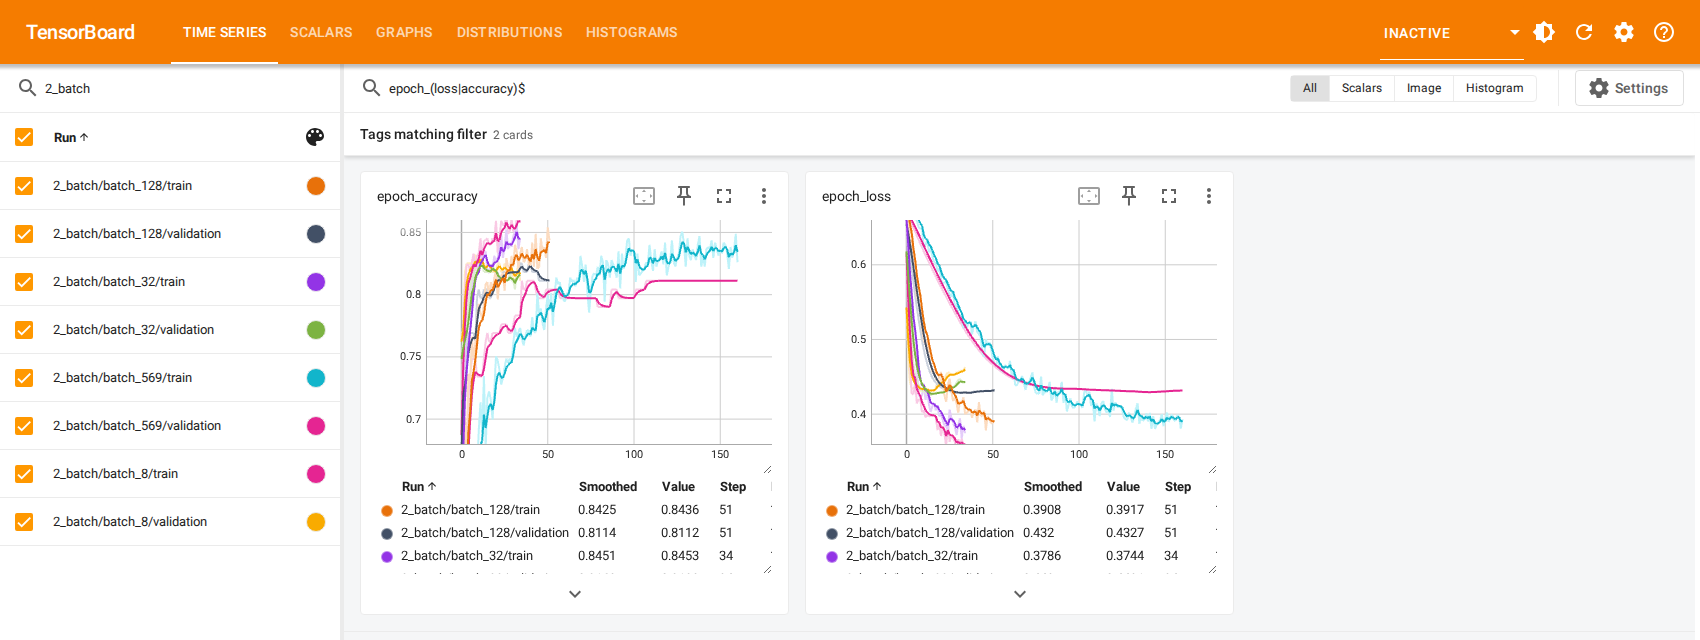

Рисунок 15 — TensorBoard, вкладка Histograms: веса слоёв итоговой сети по эпохам


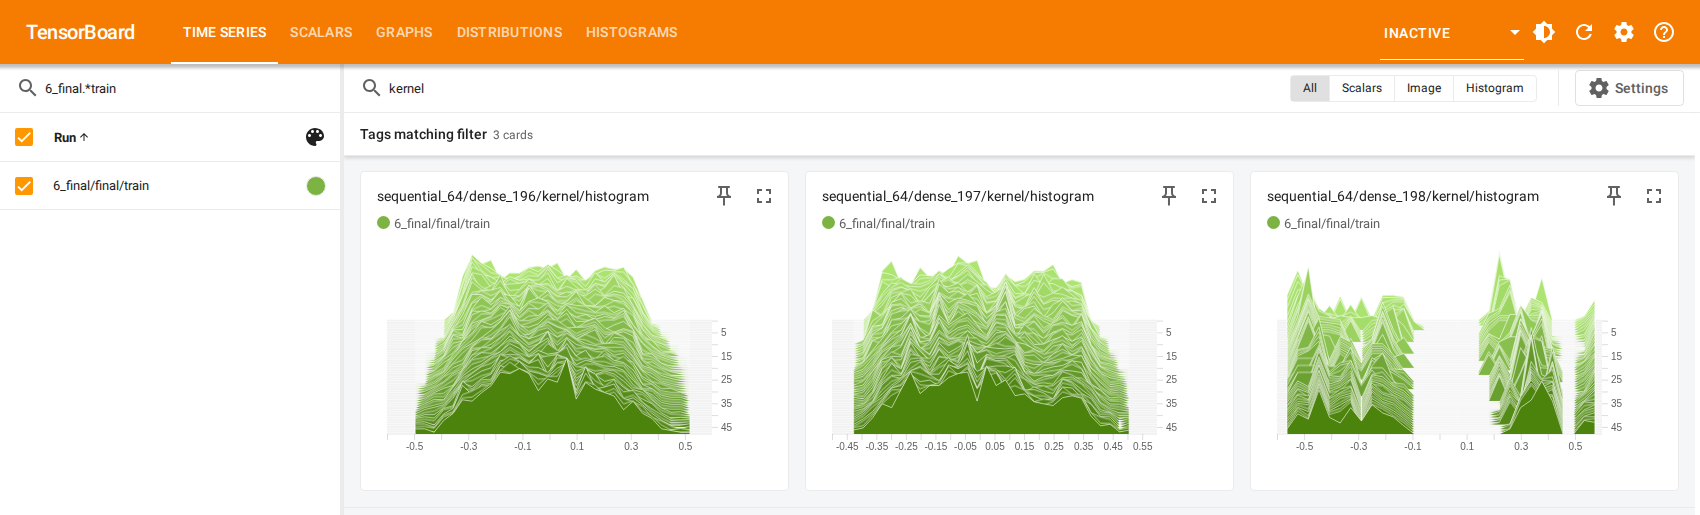

In [30]:
from IPython.display import Image, display
for f, cap in [("figs/tb_scalars.png", "Рисунок 14 — TensorBoard, вкладка Scalars: все эксперименты"),
               ("figs/tb_histograms.png", "Рисунок 15 — TensorBoard, вкладка Histograms: распределение весов по эпохам")]:
    if os.path.exists(f):
        print(cap); display(Image(f, width=1100))

**Комментарий к рисункам 13–15.**

- **Рисунок 13** построен из event-файлов TensorBoard (`EventAccumulator`) и совпадает с кривыми
  из `history` Keras (рисунок 10) — логирование работает корректно, в TensorBoard попадают те же
  значения loss и accuracy на каждой эпохе.
- **Рисунок 14 — вкладка Time Series / Scalars.** Отфильтрованы запуски эксперимента «размер батча»:
  для каждого запуска две кривые — train и validation. Видно то же, что на рисунке 9: при
  batch = 569 (розовая и голубая линии) обучение идёт в несколько раз дольше, остальные запуски
  обрываются ранней остановкой в пределах первых 50 эпох. Под графиками — таблица значений на выбранной
  эпохе; кривые сглажены (smoothing 0,6) — шум мини-батчей скрыт, тренд виден.
- **Рисунок 15 — вкладка Histograms**: распределения весов трёх слоёв итоговой сети по эпохам
  (ось глубины — номер эпохи). Первые два слоя (18→32 и 32→16) сохраняют колоколообразное
  распределение в диапазоне ±0,5 и плавно меняются от эпохи к эпохе — нет ни взрыва весов, ни их
  схлопывания к нулю, то есть обучение проходит в нормальном режиме. У выходного слоя всего
  16 весов, и они разошлись на две группы — отрицательные и положительные: часть нейронов второго
  слоя «голосует» за класс «погиб», часть — за «выжил».

TensorBoard использовался и в ходе работы: по вкладке Scalars сравнивались запуски каждого
эксперимента и определялась эпоха начала переобучения (расхождение train и validation loss).

# 7. Сравнительный анализ

Все модели — с настроенными гиперпараметрами, обучены на полной обучающей выборке (712) и оценены
на отложенной тестовой (179: 110 погибших, 69 выживших). Для моделей sklearn дополнительно
приведена 5-блочная CV — она надёжнее одного теста.

In [31]:
rows = []
for name, m in RESULTS.items():
    t = test_metrics(m)
    c = cv_metrics(m) if name != "Нейросеть (TF)" else {}
    rows.append({"метод": name, **{f"test {k}": v for k, v in t.items()},
                 "CV roc_auc": c.get("roc_auc", np.nan), "CV roc_auc std": c.get("roc_auc_std", np.nan),
                 "CV accuracy": c.get("accuracy", np.nan)})
final = pd.DataFrame(rows).set_index("метод")
print("Таблица 13 — Итоговое сравнение (test: 179 пассажиров; CV: 5-fold на train)")
final.round(4)

Таблица 13 — Итоговое сравнение (test: 179 пассажиров; CV: 5-fold на train)


,test accuracy,test precision,test recall,test f1,test roc_auc,CV roc_auc,CV roc_auc std,CV accuracy
метод,,,,,,,,
Наивный Байес,0.8045,0.7179,0.8116,0.7619,0.8503,0.8638,0.0311,0.8132
Дерево решений,0.7877,0.7541,0.6667,0.7077,0.8112,0.8476,0.0215,0.8273
LDA,0.8324,0.8000,0.7536,0.7761,0.8643,0.8745,0.0191,0.8259
SVM,0.8324,0.8095,0.7391,0.7727,0.8481,0.8570,0.0298,0.8315
kNN,0.7821,0.7885,0.5942,0.6777,0.8588,0.8574,0.0297,0.8217
Нейросеть (TF),0.7989,0.7895,0.6522,0.7143,0.8502,NaN,NaN,NaN


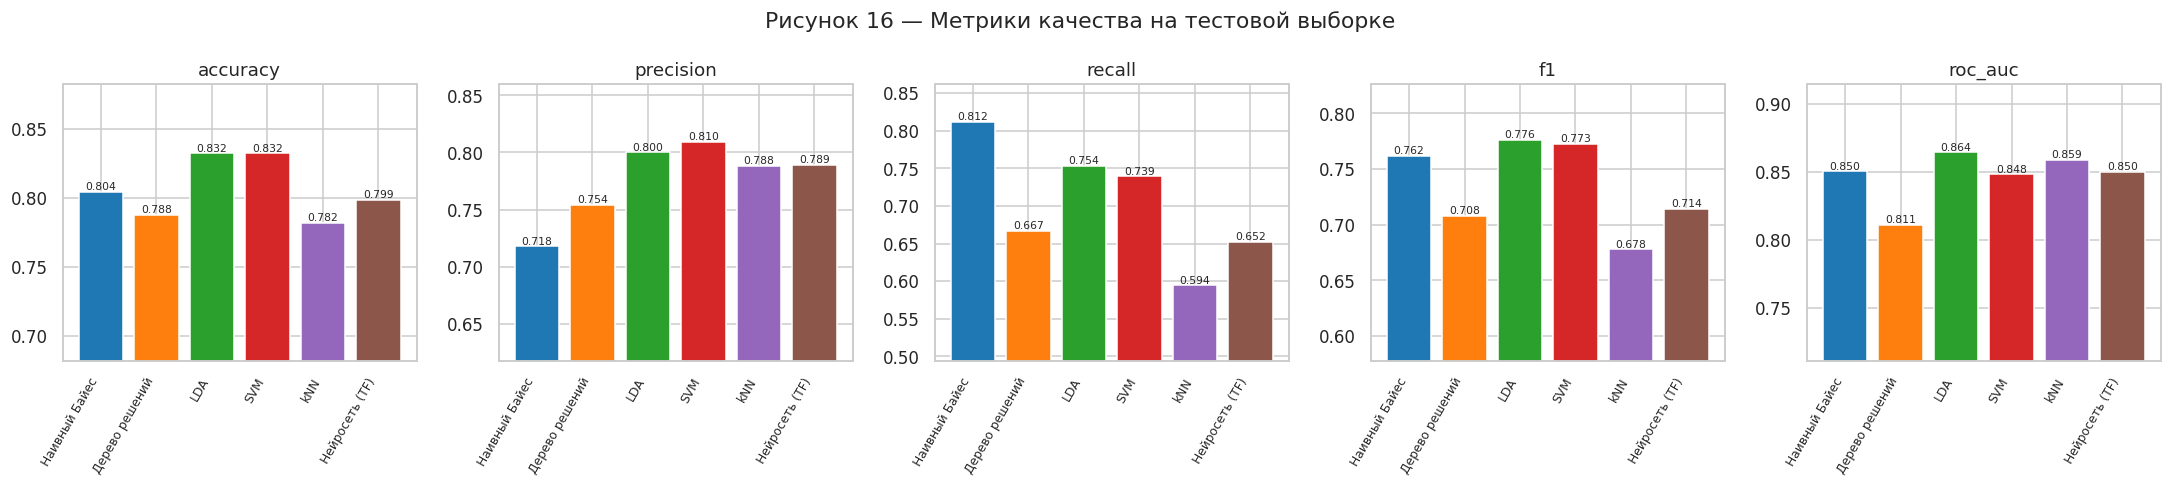

In [32]:
mets = ["accuracy", "precision", "recall", "f1", "roc_auc"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5), sharey=False)
colors = sns.color_palette("tab10", len(final))
for ax, m in zip(axes, mets):
    v = final[f"test {m}"]
    bars = ax.bar(range(len(v)), v.values, color=colors)
    ax.bar_label(bars, fmt="%.3f", fontsize=7)
    ax.set_xticks(range(len(v))); ax.set_xticklabels(v.index, rotation=60, ha="right", fontsize=8)
    ax.set_title(m); ax.set_ylim(max(0, v.min() - 0.1), min(1.0, v.max() + 0.05))
fig.suptitle("Рисунок 16 — Метрики качества на тестовой выборке")
show(fig, "16_bars")

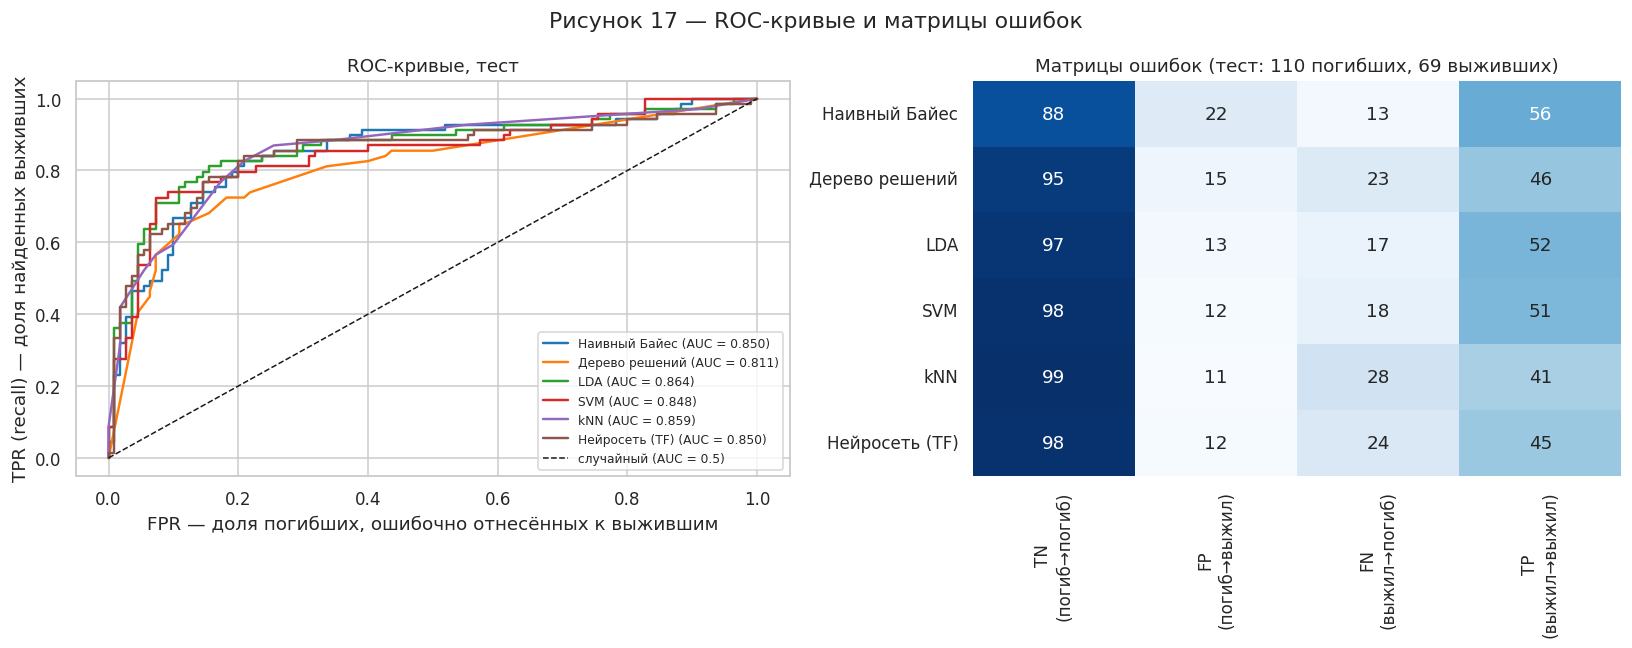

,TN\n(погиб→погиб),FP\n(погиб→выжил),FN\n(выжил→погиб),TP\n(выжил→выжил)
Наивный Байес,88,22,13,56
Дерево решений,95,15,23,46
LDA,97,13,17,52
SVM,98,12,18,51
kNN,99,11,28,41
Нейросеть (TF),98,12,24,45


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})
for (name, m), c in zip(RESULTS.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, scores_of(m, X_test))
    axes[0].plot(fpr, tpr, color=c, lw=1.6, label=f"{name} (AUC = {roc_auc_score(y_test, scores_of(m, X_test)):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="случайный (AUC = 0.5)")
axes[0].set_xlabel("FPR — доля погибших, ошибочно отнесённых к выжившим")
axes[0].set_ylabel("TPR (recall) — доля найденных выживших")
axes[0].set_title("ROC-кривые, тест"); axes[0].legend(fontsize=8, loc="lower right")
# матрицы ошибок в одной таблице
cm_rows = []
for name, m in RESULTS.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    cm_rows.append([tn, fp, fn, tp])
cm = pd.DataFrame(cm_rows, index=RESULTS.keys(), columns=["TN\n(погиб→погиб)", "FP\n(погиб→выжил)",
                                                          "FN\n(выжил→погиб)", "TP\n(выжил→выжил)"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Матрицы ошибок (тест: 110 погибших, 69 выживших)")
fig.suptitle("Рисунок 17 — ROC-кривые и матрицы ошибок")
show(fig, "17_roc")
cm

In [34]:
# Насколько надёжны различия? Бутстрэп тестовой выборки: 2000 повторных выборок с возвращением
rng = np.random.default_rng(SEED)
idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(2000)]
yt = y_test.values
boot = {}
for name, m in RESULTS.items():
    pred, sc = m.predict(X_test), scores_of(m, X_test)
    boot[name] = {"accuracy": [accuracy_score(yt[i], pred[i]) for i in idx],
                  "roc_auc": [roc_auc_score(yt[i], sc[i]) for i in idx]}
ci = pd.DataFrame({n: {"accuracy 95% ДИ": f"{np.percentile(b['accuracy'], 2.5):.3f} – {np.percentile(b['accuracy'], 97.5):.3f}",
                       "ROC-AUC 95% ДИ": f"{np.percentile(b['roc_auc'], 2.5):.3f} – {np.percentile(b['roc_auc'], 97.5):.3f}"}
                   for n, b in boot.items()}).T
print("Таблица 14 — 95 % доверительные интервалы метрик на тесте (бутстрэп)")
ci

Таблица 14 — 95 % доверительные интервалы метрик на тесте (бутстрэп)


,accuracy 95% ДИ,ROC-AUC 95% ДИ
Наивный Байес,0.743 – 0.860,0.786 – 0.908
Дерево решений,0.726 – 0.844,0.738 – 0.875
LDA,0.777 – 0.883,0.799 – 0.921
SVM,0.777 – 0.883,0.780 – 0.908
kNN,0.721 – 0.838,0.793 – 0.916
Нейросеть (TF),0.737 – 0.855,0.778 – 0.912


**Интерпретация таблицы 13 и рисунков 16–17.**

| Критерий | Лучший | Значение |
|---|---|---|
| test accuracy | **LDA, SVM** | 0,832 (149 из 179 верно) |
| test precision | SVM | 0,810 |
| test recall | наивный Байес | 0,812 |
| test F1 | **LDA** | 0,776 |
| test ROC-AUC | **LDA** | 0,864 |
| CV accuracy | SVM | 0,832 |
| CV ROC-AUC и его стабильность | **LDA** | 0,875 ± 0,019 |

- **LDA и SVM** делят первое место по accuracy. LDA лучше по F1 и ROC-AUC — и на тесте, и на CV —
  и у него самый маленький разброс по фолдам. SVM лучше по CV accuracy и precision.
- **Наивный Байес** — «щедрый» классификатор: самый высокий recall (нашёл 56 из 69 выживших),
  но и больше всех ложных тревог (22 FP, precision 0,72). Причина — нарушенное предположение
  о независимости: коррелированные признаки (`Title`, `Sex_male`, `Pclass`, `Fare_log`)
  учитываются «дважды», и вероятности становятся чрезмерно уверенными.
- **kNN** — противоположность: самый осторожный, всего 11 FP, но пропустил 28 выживших (recall 0,59).
  При этом его ROC-AUC (0,859) высокий: ранжирование хорошее, а порог «большинство из 12 соседей»
  для класса-меньшинства слишком строгий.
- **Дерево решений** — худший ROC-AUC (0,811): его «вероятности» — доли классов в листьях,
  принимающие мало различных значений, поэтому ROC-кривая ступенчатая (рисунок 17, оранжевая).
  Accuracy на тесте (0,788) ниже CV (0,827) — глубокое дерево менее устойчиво к смене выборки.
- **Нейросеть** — в середине: accuracy 0,799, ROC-AUC 0,850.
- **ROC-кривые** близки друг к другу; в важной для практики области малых FPR (до 0,1) выше всех
  LDA (зелёная): при 10 % ложных тревог она находит ≈ 74 % выживших.
- **Типичные ошибки** (на примере LDA): 16 из 17 пропущенных выживших (FN) — взрослые мужчины,
  а 11 из 13 ложно «спасённых» (FP) — женщины, из них 9 — пассажирки третьего класса. Это исключения
  из правила «женщины и дети первыми», которые не объясняются ни одним из имеющихся признаков.

**Насколько надёжны различия (таблица 14).** Тест — всего 179 пассажиров: один пассажир = 0,56 п. п.
accuracy. Ширина 95 % доверительных интервалов — около ±5,5 п. п., и интервалы всех моделей сильно
перекрываются (у LDA 0,777–0,883, у kNN 0,721–0,838). Значит, **порядок моделей на тесте нельзя
считать строгим** — поэтому выбор опирается и на кросс-валидацию (5 оценок вместо одной).

**Вывод о лучшем подходе: линейный дискриминантный анализ (LDA).**

1. Наравне с SVM — лучшая accuracy на тесте (0,832).
2. Лучший F1 и ROC-AUC на тесте и лучший ROC-AUC на кросс-валидации при наименьшем разбросе —
   самая стабильная модель.
3. Самая простая: линейная граница, нет чувствительных гиперпараметров (настройка дала +0,4 п. п.),
   обучение — доли секунды; коэффициенты интерпретируемы.
4. Её успех объясним: после построения признаков классы почти линейно разделимы — нелинейные
   методы (RBF-SVM, дерево, нейросеть) не получают преимущества, но платят за гибкость
   нестабильностью.

Если по условию задачи важнее **найти как можно больше выживших** (recall), лучший выбор —
наивный Байес (recall 0,81); если важнее **не ошибиться, назвав выжившим** (precision), — SVM.

# 8. Заключение

В работе решена задача бинарной классификации выживаемости пассажиров «Титаника» (891 пассажир,
доля выживших 38 %) пятью методами Scikit-Learn и нейронной сетью на TensorFlow.

1. **Подготовка данных.** Заполнены пропуски (`Age` — медианой с флагом пропуска, `Embarked` —
   модой), построены признаки `Title`, `FamilySize`, `IsAlone`, `HasCabin`, `Fare_log`, выполнено
   one-hot кодирование и стандартизация. Все операции со статистиками выборки вынесены в `Pipeline`
   и обучаются только на обучающих данных — утечки нет ни на тесте, ни внутри кросс-валидации.
2. **Разбиение:** 80/20 со стратификацией (712 / 179), подбор гиперпараметров — 5-блочной
   стратифицированной CV на обучающей выборке, seed фиксирован.
3. **Настройка гиперпараметров** повысила CV accuracy у всех методов: сильнее всего у дерева
   решений (+4,1 п. п. — регуляризация `min_samples_leaf` против переобучения) и kNN (+2,4 п. п. —
   выбор k и метрики), слабее всего у LDA и SVM (+0,3–0,4 п. п.), где значения по умолчанию уже
   близки к оптимальным. Показаны классические эффекты: недо- и переобучение по глубине дерева
   и числу соседей, компромисс C–gamma у SVM, роль сглаживания у наивного Байеса.
4. **Нейронная сеть** (2 скрытых слоя 32-16, ReLU, Dropout 0,5, Adam, бинарная кросс-энтропия)
   исследована в пяти экспериментах, каждая конфигурация — с тремя seed. Установлено: без ранней
   остановки сеть переобучается после ≈ 15 эпох; размер батча и функция активации влияют на скорость
   сходимости, но почти не влияют на качество; больше 2–3 слоёв не нужно; dropout — самый
   полезный регуляризатор на маленьком датасете. Обучение отслеживалось в TensorBoard
   (скаляры loss/accuracy/AUC для train и validation, гистограммы весов).
5. **Сравнение:** лучшая accuracy на тесте — у LDA и SVM (0,832), лучший F1 (0,776) и ROC-AUC
   (0,864) — у LDA, он же самый стабильный на кросс-валидации. Нейросеть (0,799) не превзошла
   классические методы — данных слишком мало, а построенные признаки делают задачу почти линейной.
   Различия между лучшими моделями лежат в пределах доверительных интервалов (±5,5 п. п.).

**Лучший подход для данного датасета — линейный дискриминантный анализ:** при равной с SVM
точности он лучше по F1 и ROC-AUC, стабильнее, проще и не требует настройки. Главный вывод
работы — на небольших табличных данных качество определяется прежде всего **построением признаков**,
а не сложностью модели: обращение `Title`, размер семьи и класс билета дали больше, чем переход
от линейной модели к нейросети.

# 9. Список источников

1. Titanic — Machine Learning from Disaster [Электронный ресурс] // Kaggle. —
   URL: https://www.kaggle.com/c/titanic (дата обращения: 14.10.2026).
2. Scikit-learn: Machine Learning in Python. User Guide: Naive Bayes, Decision Trees, Linear and
   Quadratic Discriminant Analysis, Support Vector Machines, Nearest Neighbors [Электронный ресурс]. —
   URL: https://scikit-learn.org/stable/user_guide.html
3. TensorFlow / Keras API documentation [Электронный ресурс]. — URL: https://www.tensorflow.org/api_docs
4. TensorBoard: Get started [Электронный ресурс]. — URL: https://www.tensorflow.org/tensorboard/get_started
5. Хасти Т., Тибширани Р., Фридман Дж. Основы статистического обучения. — 2-е изд. — М.: Диалектика, 2020.
6. Гудфеллоу Я., Бенджио И., Курвилль А. Глубокое обучение. — М.: ДМК Пресс, 2018.
7. Жерон О. Прикладное машинное обучение с помощью Scikit-Learn, Keras и TensorFlow. — 2-е изд. —
   М.: Диалектика, 2020.